In [2]:
import time
import h5py
import shutil
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import yaml
from scipy import stats as st
import gc
import resource


# integrated data imports
sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')
from chemrixs.average import Average
from chemrixs.smalldata import SmallData
from chemrixs.process import Reduced
from chemrixs.integrating_raw import SmallDataRaw
from chemrixs.utils import *
from pathlib import Path
from utils_jeff import *
from plotting_jeff import *
%matplotlib widget


### Reduce for 1 run

In [ ]:
def reduce(run_num, sigma_tresh=2, num_bins=33, bin_start=696.7, bin_end=709.9,
           despeckle=True, kernel_size=3, n_sigma=10, return_raw=False):
    """
    Reduce one run.

    Primary method is ADU sum-over-sum: dropletted ADU summed over shots and
    pixels (the numerator), summed I0 over the same shots (the denominator),
    divided once.  Its uncertainty comes from standard_error_IO's
    uncertainty_sum, quadratured over the emission axis.

    The mean method is computed alongside for comparison.  The photon path is
    off by default -- set photons=True to re-enable droplet_to_photons and
    the Poisson sqrt(A) sos error.

    Steps
    -----
    1.  Load raw SVLS / I0 (fims) / transmission (fzp) / TFY (APD).
    2.  Background-subtract SVLS, then threshold.
    3.  Build laser on/off and mono-bin masks.
    4.  Per bin, correlation-filter shots on I0 vs TFY.
    5.  mean    path: per-shot I0 normalisation -> mean over shots.
        sos ADU path: sum ADU over shots, sum I0 over the same shots.
    6.  Despeckle the MEAN maps only, then collapse the emission axis.

    Parameters
    ----------
    shot_roi : (lo, hi) or None
        Pixel slice summed to form the per-shot scalars used by the
        normalisation study.  None sums every pixel.  Narrow it to the
        emission line: summing several hundred empty pixels buries the
        droplets under noise and makes normalisation look less effective
        than it is.
    despeckle : bool
        Mean maps only.  The ADU sums are deliberately not despeckled: on a
        sparse map a pixel well above its neighbours is usually a legitimate
        droplet, and clipping it biases low exactly where statistics are
        thinnest.
    return_raw : bool
        Also return the per-shot 2-D arrays, ~0.5 GB per run.  Leave False
        when looping over runs in average(); the 1-D shot_* scalars below
        are returned regardless.

    Returns
    -------
    dict with keys:
      scanvar                             (num_bins,)  bin centres [eV]
      counts_{on,off}[_filtered]          (num_bins,)  shots per bin
      frames_dropped_{on,off}             (num_bins,)  % dropped by filter

      -- ADU sum-over-sum (primary) --
      PFY_{on,off}_sosadu[_filtered]      (num_bins,)  A / sum(I0)
      PFY_{on,off}_sosadu[_filtered]_err  (num_bins,)  dA / sum(I0)
      adu_sum_{on,off}[_filtered]         (num_bins, n_pix)  A per pixel
      adu_err_{on,off}[_filtered]         (num_bins, n_pix)  its uncertainty
      adu_total_{on,off}[_filtered]       (num_bins,)  A collapsed
      i0_sum_{on,off}[_filtered]          (num_bins,)  summed I0 = exposure

      -- mean method --
      PFY_{on,off}_mean[_filtered]        (num_bins,)
      PFY_{on,off}_mean[_filtered]_err    (num_bins,)
      map_{on,off}_mean[_filtered]        (num_bins, n_pix)  RIXS map
      err_{on,off}_mean[_filtered]        (num_bins, n_pix)

      -- photon sos, only if photons=True --
      photons_{on,off}[_filtered]         (num_bins, n_pix)
      photons_{on,off}[_filtered]_total   (num_bins,)
      PFY_{on,off}_sos[_filtered][_err]   (num_bins,)
      d2p_details

      -- per-shot 1-D scalars, always returned, ~4 MB/run --
      shot_adu, shot_adu_norm, shot_i0, shot_tfy, shot_n_bad,
      shot_bin_idx, shot_{laser,filtered}_{on,off}, shot_roi

      E_emi (n_pix,), emi_calib, fzp_{on,off} (num_bins,)

    Pool adu_total_* and i0_sum_* across runs and divide once, or
    weighted-average the per-run PFY_*_sosadu -- with uncertainty_sum ~
    sqrt(N) the weights come out proportional to exposure and the two are
    algebraically identical.  Do NOT plain-average PFY_*_sosadu.
    """
    t0 = time.time()

    # ------------------------------------------------------------------
    # 1. Load raw data
    # ------------------------------------------------------------------
    
    # yaml config
    fyaml = '../roi_input_jeff.yml'
    with open(fyaml) as f:
        cfg = yaml.safe_load(f)
    fim0_cfg, fim1_cfg = cfg['fim0'], cfg['fim1']
    fzp_cfg, evc_cfg = cfg['fzp'], cfg['evc']
    mono_cfg = cfg['mono_calib']
    thresh_min, thresh_max = cfg['svls']['threshold']
    apd_cfg = cfg['apd']
    emi_calib_cfg = cfg['emi_calib']

    d2p_cfg = dict(cfg['d2p'])
    verbose_d2p = bool(d2p_cfg.pop('return_details', True))
    
    # JW edit 9/3/26: background run selection
    bg_run_cfg = cfg['bg_run']
    
    
    ## JW edit 9/3/26: determine the background run
    for bg_run_config in bg_run_cfg:
        if (run_num>=bg_run_config[0]) and (run_num<=bg_run_config[1]):
            bg_run_num = bg_run_config[2]
            break

    base = '/sdf/data/lcls/ds/rix/'
    exp = 'rix101231825'
    fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run_num:04d}.h5'
    bg_path = (f'/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/'
                  f'DataAcceleratorChemRIXS/jupyter_notebook/proc/BG_run{bg_run_num}.h5')

    t_load = time.time()
    with h5py.File(bg_path, 'r') as h5:
        bg_proc = h5['axis_svls'][:]

    with h5py.File(fname, 'r') as h5:
        timestamp = h5['intg/timestamp'][:]
        g = h5['intg/axis_svls']
        count = g['count'][:].squeeze()
        event_codes = g['timing_sum_eventcodes'][:]
        monoenc = g['mono_hrencoder_sum_value'][:].squeeze()
        fim0_wf = g['det_rix_fim0_sum_full_area'][:]
        fim1_wf = g['det_rix_fim1_sum_full_area'][:]
        svls_proj = g['droplet_dense_curve_corr_pj_ax_1_data'][:]
        fzp = g['fzp_piranha_sum_full_area'][:]
        apd_wf = g['det_crix_w8_sum_full_area'][:]
    print(f"  h5 read: {time.time()-t_load:.1f}s")

    t_proc = time.time()

    # ------------------------------------------------------------------
    # 1b. Sort by timestamp, then roll SVLS by one frame
    # ------------------------------------------------------------------
    sort_idx = np.argsort(timestamp)
    timestamp = timestamp[sort_idx]
    count = count[sort_idx]
    event_codes = event_codes[sort_idx]
    monoenc = monoenc[sort_idx]
    fim0_wf = fim0_wf[sort_idx]
    fim1_wf = fim1_wf[sort_idx]
    svls_proj = svls_proj[sort_idx]
    fzp = fzp[sort_idx]
    apd_wf = apd_wf[sort_idx]

    svls_proj = np.roll(svls_proj, shift=1, axis=0)

    timestamp = timestamp[1:]
    count = count[1:]
    fim0_wf = fim0_wf[1:]
    fim1_wf = fim1_wf[1:]
    svls_proj = svls_proj[1:]
    fzp = fzp[1:]
    monoenc = monoenc[1:]
    event_codes = event_codes[1:]
    apd_wf = apd_wf[1:]

    mono = get_mono(monoenc, mono_cfg, run_num, count)

    # ------------------------------------------------------------------
    # 2. Per-frame detector processing
    # ------------------------------------------------------------------
    svls_adu = svls_proj - bg_proc
    del svls_proj

    n_frames, n_pix = svls_adu.shape

    # emission axis: a per-pixel label, resolved here so the run-range lookup
    # uses this run's own number rather than requiring every run in an
    # average to share one calibration entry
    E_emi, emi_calib = get_emission_axis(run_num, emi_calib_cfg, n_pix)

    # background subtraction FIRST, then threshold, so that off-pixels land
    # at exactly 0 rather than at -bg_proc
    svls_adu[svls_adu > thresh_max] = np.nan   # reject, don't record as zero
    svls_adu[svls_adu < thresh_min] = 0.0      # floor noise; NaN unaffected


    I0_int = (i0_sum(fim0_wf, fim0_cfg) + i0_sum(fim1_wf, fim1_cfg)).flatten()
    tfy_int = i0_sum(apd_wf, apd_cfg).flatten()

    bg_0 = fzp[:, fzp_cfg['offset_roi'][0]:fzp_cfg['offset_roi'][1]].mean(axis=1)
    fzp_bgsub = fzp - bg_0[:, np.newaxis]
    fzp_proj = fzp_bgsub[:, fzp_cfg['roi'][0]:fzp_cfg['roi'][1]].sum(axis=1).flatten()

    # ------------------------------------------------------------------
    # 3. Masks
    # ------------------------------------------------------------------
    expected_count = st.mode(count, keepdims=False)[0]
    laser_on = np.asarray(event_codes[:, evc_cfg[True]] / expected_count > 0.5).squeeze()
    laser_off = np.asarray(event_codes[:, evc_cfg[False]] / expected_count > 0.5).squeeze()

    # A shot at I0 = 1e3 against a 4e6 median passes `I0 > 0` and then enters
    # the mean path as a per-shot value ~4000x too large. Cut relative to the
    # run's own median instead.
    finite_i0 = np.isfinite(I0_int) & (I0_int > 0)
    med_i0 = np.median(I0_int[finite_i0]) if finite_i0.any() else 0.0
    good_i0 = finite_i0 & (I0_int > 0.10 * med_i0)
    n_lowi0 = int(finite_i0.sum() - good_i0.sum())
    if n_lowi0:
        print(f"  dropped {n_lowi0} shots below 10% of median I0 "
              f"({med_i0:.3e})")

    laser_on &= good_i0
    laser_off &= good_i0
#####################################################################################################################################################
    bin_idx, bin_centers = bin_mono_energy(mono, num_bins, (bin_start, bin_end))

    # per-shot normalised map, built once outside the bin loop (mean path)
    svls_norm_2d = svls_adu / I0_int[:, np.newaxis]
    fzp_norm = fzp_proj / I0_int

    # ------------------------------------------------------------------
    # 4-6. Filter, bin into 2-D maps + errors
    # ------------------------------------------------------------------
    Z = lambda: np.zeros((num_bins, n_pix))
    ZI = lambda: np.zeros((num_bins, n_pix), dtype=np.int64)
    z = lambda: np.zeros(num_bins)

    map_on_mean, map_off_mean = Z(), Z()
    map_on_mean_f, map_off_mean_f = Z(), Z()
    err_on_mean, err_off_mean = Z(), Z()
    err_on_mean_f, err_off_mean_f = Z(), Z()

    # summed ADU + its uncertainty -- the sos numerator and its error
    adu_on, adu_off = Z(), Z()
    adu_on_f, adu_off_f = Z(), Z()
    aerr_on, aerr_off = Z(), Z()
    aerr_on_f, aerr_off_f = Z(), Z()

    i0_on, i0_off = z(), z()
    i0_on_f, i0_off_f = z(), z()

    counts_on, counts_off = z(), z()
    counts_on_f, counts_off_f = z(), z()
    frames_dropped_on, frames_dropped_off = z(), z()

    fzp_on, fzp_off = np.full(num_bins, np.nan), np.full(num_bins, np.nan)

    filt_on_all = np.zeros(n_frames, dtype=bool)
    filt_off_all = np.zeros(n_frames, dtype=bool)

    def _fill(mask, i, m_mean, e_mean, adu_arr, aerr_arr, i0_arr):
        """One bin row: mean map, ADU sum + its error, photons, I0 sum."""
        # mean path: value + SE of the mean, from the I0-normalised matrix
        _, _, datmean, se_mean = standard_error_IO(svls_norm_2d[mask])
        m_mean[i] = datmean
        e_mean[i] = se_mean
        # ADU sos path: summed ADU over shots and its uncertainty, from the
        # UN-normalised matrix; plus the exposure over the same shots
        datsum, unc_sum, _, _ = standard_error_IO(svls_adu[mask])
        adu_arr[i] = datsum
        aerr_arr[i] = unc_sum
        i0_arr[i] = np.nansum(I0_int[mask])

    for i in range(num_bins):
        mask_bins_on = (bin_idx == i) & laser_on
        mask_bins_off = (bin_idx == i) & laser_off

        # Filter with fzp
        filtered_mask_on, *_, info_on = filter_correlation(
            I0_int, fzp_proj, mask_bins_on, verbose=False, sigma_thresh=sigma_tresh)
        filtered_mask_off, *_, info_off = filter_correlation(
            I0_int, fzp_proj, mask_bins_off, verbose=False, sigma_thresh=sigma_tresh)

        filt_on_all |= filtered_mask_on
        filt_off_all |= filtered_mask_off

        counts_on[i] = mask_bins_on.sum()
        counts_off[i] = mask_bins_off.sum()
        counts_on_f[i] = filtered_mask_on.sum()
        counts_off_f[i] = filtered_mask_off.sum()

        frames_dropped_on[i] = info_on['pct_dropped']
        frames_dropped_off[i] = info_off['pct_dropped']

        # empty bins stay zero with zero error -- downstream that carries no
        # weight, and it avoids NaNs poisoning the multi-run average
        if counts_on[i]:
            _fill(mask_bins_on, i, map_on_mean, err_on_mean,
                  adu_on, aerr_on, i0_on)
            fzp_on[i] = fzp_norm[mask_bins_on].mean()
        if counts_off[i]:
            _fill(mask_bins_off, i, map_off_mean, err_off_mean,
                  adu_off, aerr_off, i0_off)
            fzp_off[i] = fzp_norm[mask_bins_off].mean()
        if counts_on_f[i]:
            _fill(filtered_mask_on, i, map_on_mean_f, err_on_mean_f,
                  adu_on_f, aerr_on_f, i0_on_f)
        if counts_off_f[i]:
            _fill(filtered_mask_off, i, map_off_mean_f, err_off_mean_f,
                  adu_off_f, aerr_off_f, i0_off_f)

    # ------------------------------------------------------------------
    # 6b. Despeckle the MEAN maps only, then collapse the emission axis
    # ------------------------------------------------------------------
    if despeckle:
        map_on_mean, _ = despeckle_map(map_on_mean, kernel_size, n_sigma,
                                       verbose=False, label='on_mean')
        map_off_mean, _ = despeckle_map(map_off_mean, kernel_size, n_sigma,
                                        verbose=False, label='off_mean')
        map_on_mean_f, _ = despeckle_map(map_on_mean_f, kernel_size, n_sigma,
                                         verbose=False, label='on_mean_filtered')
        map_off_mean_f, _ = despeckle_map(map_off_mean_f, kernel_size, n_sigma,
                                          verbose=False, label='off_mean_filtered')

    def _collapse(m, e):
        """Sum the emission axis; add pixel errors in quadrature."""
        return np.nansum(m, axis=1), np.sqrt(np.nansum(e**2, axis=1))

    def _collapse_sos_adu(m, e, i0):
        """Sum the emission axis, then divide once by that bin's sum(I0).
        Numerator and denominator are both summed BEFORE the division --
        that is what makes it sum-over-sum."""
        num = np.nansum(m, axis=1)
        num_err = np.sqrt(np.nansum(e**2, axis=1))
        val = np.divide(num, i0, out=np.zeros_like(num), where=i0 > 0)
        err = np.divide(num_err, i0, out=np.zeros_like(num_err), where=i0 > 0)
        return num, val, err

    PFY_on_mean, PFY_on_mean_err = _collapse(map_on_mean, err_on_mean)
    PFY_off_mean, PFY_off_mean_err = _collapse(map_off_mean, err_off_mean)
    PFY_on_mean_f, PFY_on_mean_f_err = _collapse(map_on_mean_f, err_on_mean_f)
    PFY_off_mean_f, PFY_off_mean_f_err = _collapse(map_off_mean_f, err_off_mean_f)

    Aa_on, PFY_on_sosadu, PFY_on_sosadu_err = _collapse_sos_adu(
        adu_on, aerr_on, i0_on)
    Aa_off, PFY_off_sosadu, PFY_off_sosadu_err = _collapse_sos_adu(
        adu_off, aerr_off, i0_off)
    Aa_on_f, PFY_on_sosadu_f, PFY_on_sosadu_f_err = _collapse_sos_adu(
        adu_on_f, aerr_on_f, i0_on_f)
    Aa_off_f, PFY_off_sosadu_f, PFY_off_sosadu_f_err = _collapse_sos_adu(
        adu_off_f, aerr_off_f, i0_off_f)

    out = {
        'scanvar': bin_centers,
        'counts_on': counts_on, 'counts_off': counts_off,
        'counts_on_filtered': counts_on_f, 'counts_off_filtered': counts_off_f,
        'frames_dropped_on': frames_dropped_on,
        'frames_dropped_off': frames_dropped_off,
        'n_lowi0_dropped': n_lowi0, 'median_i0': med_i0,

        # ---- ADU sum-over-sum (primary) -----------------------------------------------------------------
        'PFY_on_sosadu': PFY_on_sosadu, 'PFY_on_sosadu_err': PFY_on_sosadu_err,
        'PFY_off_sosadu': PFY_off_sosadu, 'PFY_off_sosadu_err': PFY_off_sosadu_err,
        'PFY_on_sosadu_filtered': PFY_on_sosadu_f,
        'PFY_on_sosadu_filtered_err': PFY_on_sosadu_f_err,
        'PFY_off_sosadu_filtered': PFY_off_sosadu_f,
        'PFY_off_sosadu_filtered_err': PFY_off_sosadu_f_err,

        # un-divided sos ingredients: pool these across runs
        'adu_sum_on': adu_on, 'adu_sum_off': adu_off,
        'adu_sum_on_filtered': adu_on_f, 'adu_sum_off_filtered': adu_off_f,
        'adu_err_on': aerr_on, 'adu_err_off': aerr_off,
        'adu_err_on_filtered': aerr_on_f, 'adu_err_off_filtered': aerr_off_f,
        'adu_total_on': Aa_on, 'adu_total_off': Aa_off,
        'adu_total_on_filtered': Aa_on_f, 'adu_total_off_filtered': Aa_off_f,
        'i0_sum_on': i0_on, 'i0_sum_off': i0_off,
        'i0_sum_on_filtered': i0_on_f, 'i0_sum_off_filtered': i0_off_f,

        # ---- mean method ----
        'PFY_on_mean': PFY_on_mean, 'PFY_on_mean_err': PFY_on_mean_err,
        'PFY_off_mean': PFY_off_mean, 'PFY_off_mean_err': PFY_off_mean_err,
        'PFY_on_mean_filtered': PFY_on_mean_f,
        'PFY_on_mean_filtered_err': PFY_on_mean_f_err,
        'PFY_off_mean_filtered': PFY_off_mean_f,
        'PFY_off_mean_filtered_err': PFY_off_mean_f_err,
        'map_on_mean': map_on_mean, 'err_on_mean': err_on_mean,
        'map_off_mean': map_off_mean, 'err_off_mean': err_off_mean,
        'map_on_mean_filtered': map_on_mean_f,
        'err_on_mean_filtered': err_on_mean_f,
        'map_off_mean_filtered': map_off_mean_f,
        'err_off_mean_filtered': err_off_mean_f,

        # ---- per-shot 1-D scalars ----

        'shot_i0': I0_int.astype(np.float64),
        'shot_tfy': tfy_int.astype(np.float32),
        'shot_bin_idx': bin_idx.astype(np.int16),
        'shot_laser_on': laser_on, 'shot_laser_off': laser_off,
        'shot_filtered_on': filt_on_all, 'shot_filtered_off': filt_off_all,

        'E_emi': E_emi, 'emi_calib': emi_calib,
        'fzp_on': fzp_on, 'fzp_off': fzp_off,
    }

    if return_raw:
        out.update({
            'raw_svls_adu': raw_adu_out,
            'raw_photons': photons_shot,
            'raw_i0': I0_int,
            'raw_bin_idx': bin_idx,
            'raw_laser_on': laser_on, 'raw_laser_off': laser_off,
            'raw_filtered_on': filt_on_all, 'raw_filtered_off': filt_off_all,
        })

    # tfy_int is NOT deleted -- it is returned as shot_tfy
    del fim0_wf, fim1_wf, fzp, apd_wf, fzp_bgsub, svls_norm_2d
    if not return_raw:
        del svls_adu, photons_shot, raw_adu_out
    gc.collect()

    print(f"  processing: {time.time()-t_proc:.1f}s")
    print(f"run {run_num}: {time.time()-t0:.1f}s, "
          f"peak RSS {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1e6:.1f} GB")

    return out



  h5 read: 0.8s
  dropped 822 shots below 10% of median I0 (3.669e+06)


/sdf/home/j/jwang343/miniconda3/envs/dachemrixs/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


  processing: 2.3s
run 178: 3.0s, peak RSS 5.1 GB
(33,)
(33,)
(33,)
(33,)
(33,)
(33,)
(33,)
(33,)
(33,)


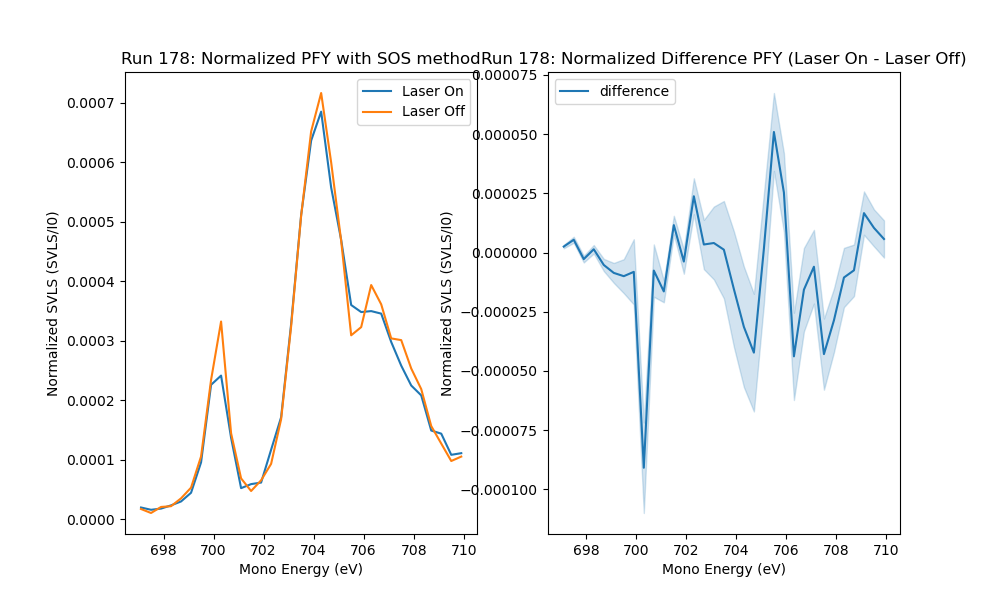

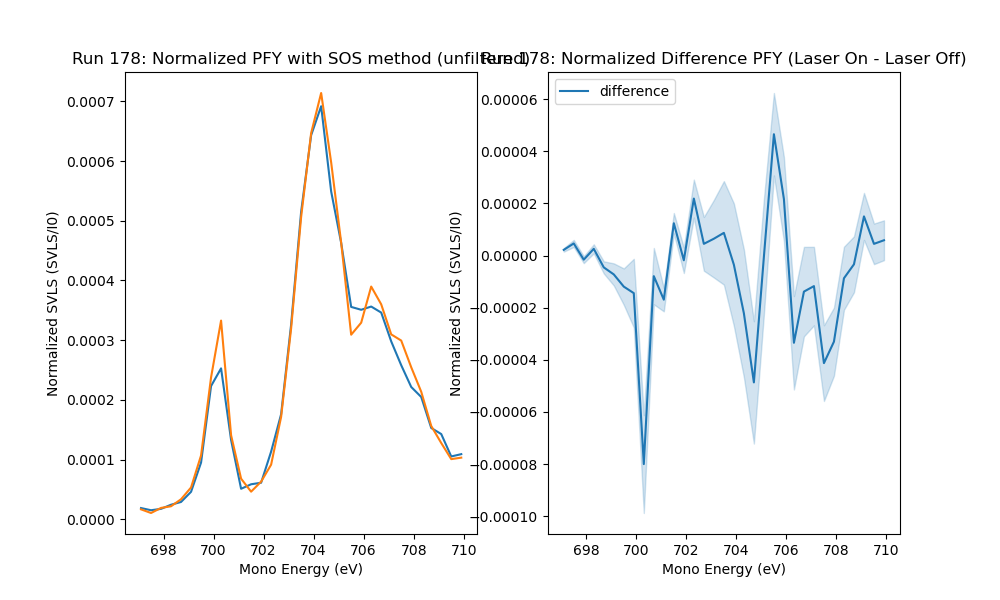

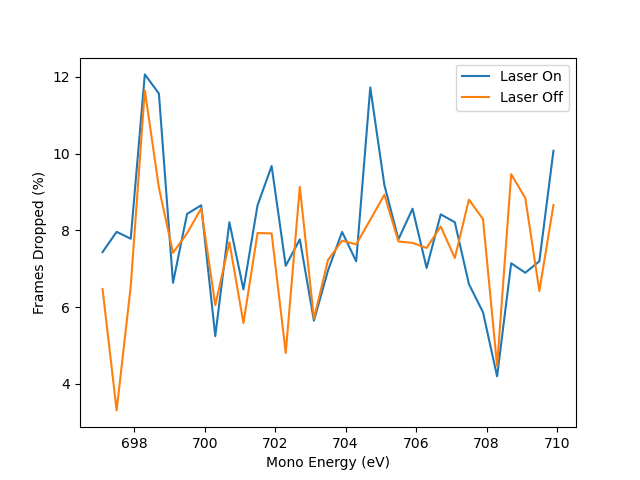

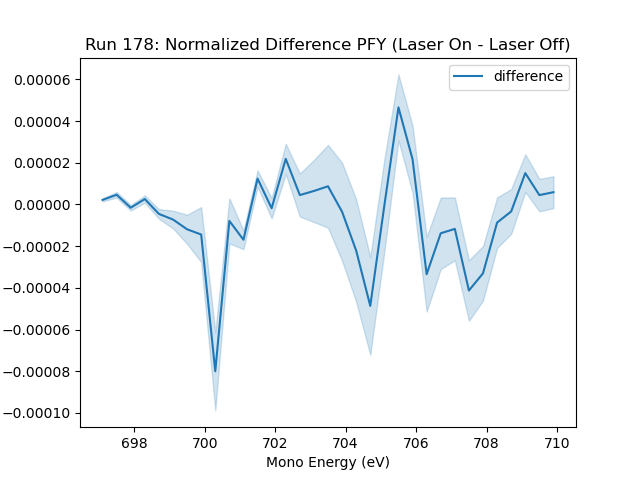

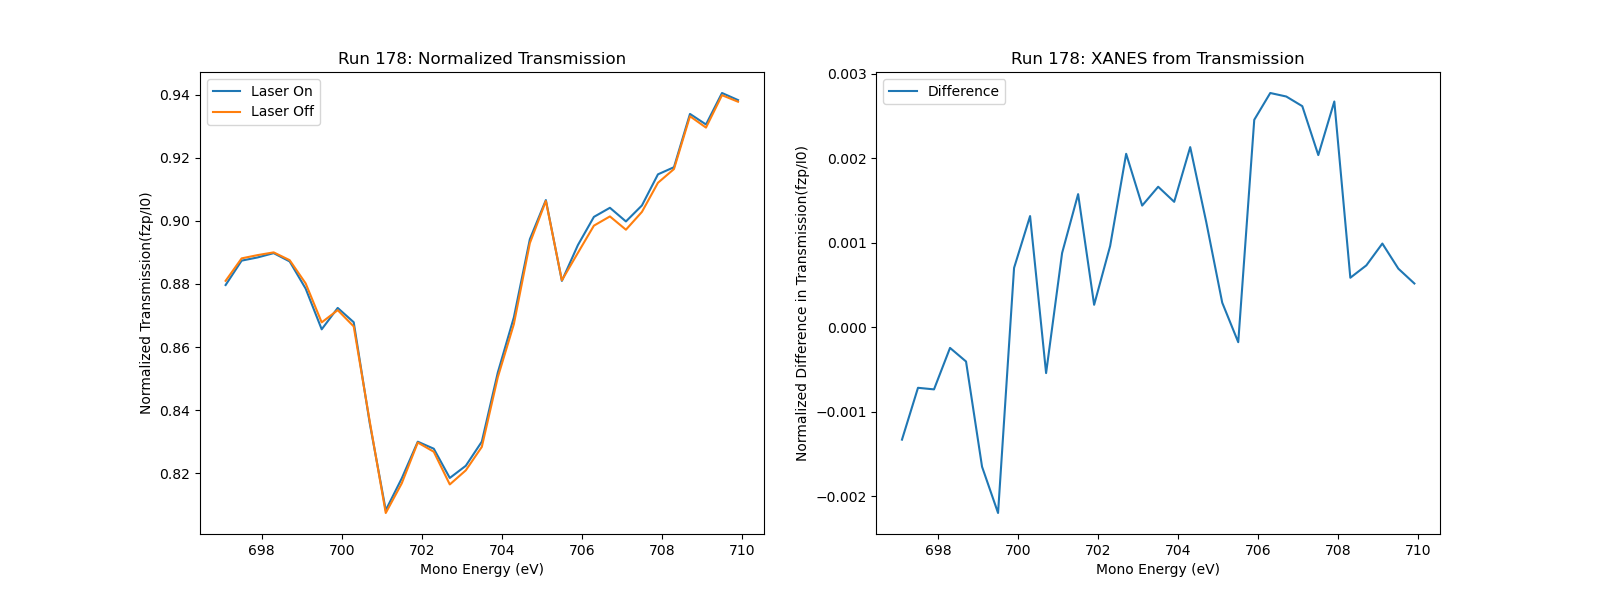

In [18]:
run_num = 178
r = reduce(run_num=run_num, sigma_tresh=2, num_bins = 33, bin_start = 696.9, bin_end = 710.1)

print(r['counts_on'].shape)
print(r['counts_on_filtered'].shape)
print(r['counts_off'].shape)
print(r['counts_off_filtered'].shape)
print(r['PFY_on_mean'].shape)
print(r['PFY_on_mean_filtered'].shape)
print(r['PFY_off_mean'].shape)
print(r['PFY_off_mean_filtered'].shape)
print(r['scanvar'].shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 6))
ax[0].plot(r['scanvar'], r['PFY_on_sosadu_filtered'], markersize=0.5, label='Laser On')
ax[0].plot(r['scanvar'], r['PFY_off_sosadu_filtered'], markersize=0.5, label='Laser Off')
ax[0].set_title(f'Run {run_num}: Normalized PFY with SOS method')
ax[0].set_xlabel('Mono Energy (eV)')
ax[0].set_ylabel('Normalized SVLS (SVLS/I0)')
ax[0].legend()

ax[1].plot(r['scanvar'], r['PFY_on_sosadu_filtered'] - r['PFY_off_sosadu_filtered'], markersize=0.5, label='difference')
dPFYerr = np.sqrt(r['PFY_on_sosadu_filtered_err']**2 + r['PFY_off_sosadu_filtered_err']**2)
ax[1].fill_between(r['scanvar'],
                    (r['PFY_on_sosadu_filtered'] - r['PFY_off_sosadu_filtered']) - dPFYerr,
                    (r['PFY_on_sosadu_filtered'] - r['PFY_off_sosadu_filtered']) + dPFYerr,
                    alpha=0.2, color='tab:blue')
ax[1].set_title(f'Run {run_num}: Normalized Difference PFY (Laser On - Laser Off)')
ax[1].set_xlabel('Mono Energy (eV)')
ax[1].set_ylabel('Normalized SVLS (SVLS/I0)')
ax[1].legend()
plt.show()


# plot out the normal spectrum before removing any shots
fig1, ax1 = plt.subplots(1, 2, figsize=(10, 6))
ax1[0].plot(r['scanvar'], r['PFY_on_sosadu'], markersize=0.5, label='Laser On')
ax1[0].plot(r['scanvar'], r['PFY_off_sosadu'], markersize=0.5, label='Laser Off')
ax1[0].set_title(f'Run {run_num}: Normalized PFY with SOS method (unfiltered)')
ax1[0].set_xlabel('Mono Energy (eV)')
ax1[0].set_ylabel('Normalized SVLS (SVLS/I0)')

ax1[1].plot(r['scanvar'], r['PFY_on_sosadu'] - r['PFY_off_sosadu'], markersize=0.5, label='difference')
dPFYerr_unfiltered = np.sqrt(r['PFY_on_sosadu_err']**2 + r['PFY_off_sosadu_err']**2)
ax1[1].fill_between(r['scanvar'],
                    (r['PFY_on_sosadu'] - r['PFY_off_sosadu']) - dPFYerr_unfiltered,
                    (r['PFY_on_sosadu'] - r['PFY_off_sosadu']) + dPFYerr_unfiltered,
                    alpha=0.2, color='tab:blue')
ax1[1].set_title(f'Run {run_num}: Normalized Difference PFY (Laser On - Laser Off)')
ax1[1].set_xlabel('Mono Energy (eV)')
ax1[1].set_ylabel('Normalized SVLS (SVLS/I0)')
ax1[1].legend()
plt.show()

plt.figure()
plt.plot(r['scanvar'], r['frames_dropped_on'], markersize=0.5, label='Laser On')
plt.plot(r['scanvar'], r['frames_dropped_off'], markersize=0.5, label='Laser Off')
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Frames Dropped (%)')
plt.legend()
plt.show()

fig, ax = plt.subplots(1, 2 , figsize = (16,6))
ax[0].plot(r['scanvar'], r['fzp_on'], label = "Laser On")
ax[0].plot(r['scanvar'], r['fzp_off'], label = "Laser Off")
ax[0].set_title(f'Run {run_num}: Normalized Transmission')
ax[0].set_xlabel('Mono Energy (eV)')
ax[0].set_ylabel('Normalized Transmission(fzp/I0)')
ax[0].legend()

ax[1].plot(r['scanvar'], r['fzp_on'] - r['fzp_off'], label="Difference")
ax[1].set_title(f'Run {run_num}: XANES from Transmission')
ax[1].set_xlabel('Mono Energy (eV)')
ax[1].set_ylabel('Normalized Difference in Transmission(fzp/I0)')
ax[1].legend()


plt.figure()

plt.plot(r['scanvar'], r['PFY_on_sosadu'] - r['PFY_off_sosadu'], markersize=0.5, label='difference')
dPFYerr_unfiltered = np.sqrt(r['PFY_on_sosadu_err']**2 + r['PFY_off_sosadu_err']**2)
plt.fill_between(r['scanvar'],
                    (r['PFY_on_sosadu'] - r['PFY_off_sosadu']) - dPFYerr_unfiltered,
                    (r['PFY_on_sosadu'] - r['PFY_off_sosadu']) + dPFYerr_unfiltered,
                    alpha=0.2, color='tab:blue')
plt.title(f'Run {run_num}: Normalized Difference PFY (Laser On - Laser Off)')
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Normalized SVLS (SVLS/I0)')
plt.legend()
plt.show()



scanvar = r['scanvar']

### Run-to-Run fluctuations of the sum over sum values
- plot scatter plots of SVLS signal against I0 for each bin across runs

In [104]:
pyridine_runs = [112,114,115,116,117,118,119,120,121,122,123,127,138,139,140,141,145]
pyridine_selected_runs = [112, 114, 115, 117,118, 120, 121, 122,123,138, 141 ]
pyridine_selected_runs_v2 = [112, 114, 115,116, 117,118, 119, 120, 121, 122,123, 127, 141]
# runs = [112,114,115]

# unfiltered raw sos & i0 values
pyridine_sos_on = []
pyridine_sos_off = []

pyridine_i0_on = []
pyridine_i0_off = []




# filtered, all the filtered keys just add a "f" at the end
pyridine_sos_on_f = []
pyridine_sos_off_f = []
pyridine_i0_on_f = []
pyridine_i0_off_f = []



# processed values that are sos but not raw, right now just the ground state spectrum should be enough, just comparing the shifts
pyridine_sos_off_norm = []








for i in pyridine_selected_runs_v2:
    r = reduce(i, sigma_tresh=1.8)
    pyridine_sos_on.append(r['adu_total_on'])
    pyridine_sos_off.append(r['adu_total_off'])
    pyridine_i0_on.append(r['i0_sum_on'])
    pyridine_i0_off.append(r['i0_sum_off'])
    
    
    pyridine_sos_on_f.append(r['adu_total_on_filtered'])
    pyridine_sos_off_f.append(r['adu_total_off_filtered'])
    pyridine_i0_on_f.append(r['i0_sum_on_filtered'])
    pyridine_i0_off_f.append(r['i0_sum_off_filtered'])
    
    pyridine_sos_off_norm.append(r['PFY_off_sosadu'])



pyridine_sos_on = np.array(pyridine_sos_on)
pyridine_sos_off = np.array(pyridine_sos_off)
pyridine_i0_on = np.array(pyridine_i0_on) 
pyridine_i0_off = np.array(pyridine_i0_off)

pyridine_sos_on_f = np.array(pyridine_sos_on_f)
pyridine_sos_off_f = np.array(pyridine_sos_off_f)
pyridine_i0_on_f = np.array(pyridine_i0_on_f)
pyridine_i0_off_f = np.array(pyridine_i0_off_f)

pyridine_sos_off_norm = np.array(pyridine_sos_off_norm)

  h5 read: 1.0s
  dropped 6 shots below 10% of median I0 (3.864e+06)
  processing: 2.2s
run 112: 3.2s, peak RSS 5.7 GB
  h5 read: 0.8s
  dropped 7 shots below 10% of median I0 (3.929e+06)
  processing: 2.2s
run 114: 3.0s, peak RSS 5.7 GB
  h5 read: 0.9s
  dropped 19 shots below 10% of median I0 (3.870e+06)
  processing: 2.1s
run 115: 3.0s, peak RSS 5.7 GB
  h5 read: 1.0s
  processing: 2.1s
run 116: 3.2s, peak RSS 5.7 GB
  h5 read: 0.9s
  dropped 15 shots below 10% of median I0 (3.919e+06)
  processing: 2.1s
run 117: 3.0s, peak RSS 5.7 GB
  h5 read: 1.0s
  dropped 263 shots below 10% of median I0 (3.928e+06)
  processing: 2.1s
run 118: 3.1s, peak RSS 5.7 GB
  h5 read: 0.9s
  dropped 6 shots below 10% of median I0 (3.969e+06)
  processing: 2.1s
run 119: 3.1s, peak RSS 5.7 GB
  h5 read: 0.9s
  dropped 7 shots below 10% of median I0 (4.017e+06)
  processing: 2.1s
run 120: 3.0s, peak RSS 5.7 GB
  h5 read: 1.0s
  dropped 16 shots below 10% of median I0 (4.112e+06)
  processing: 2.1s
run 121:

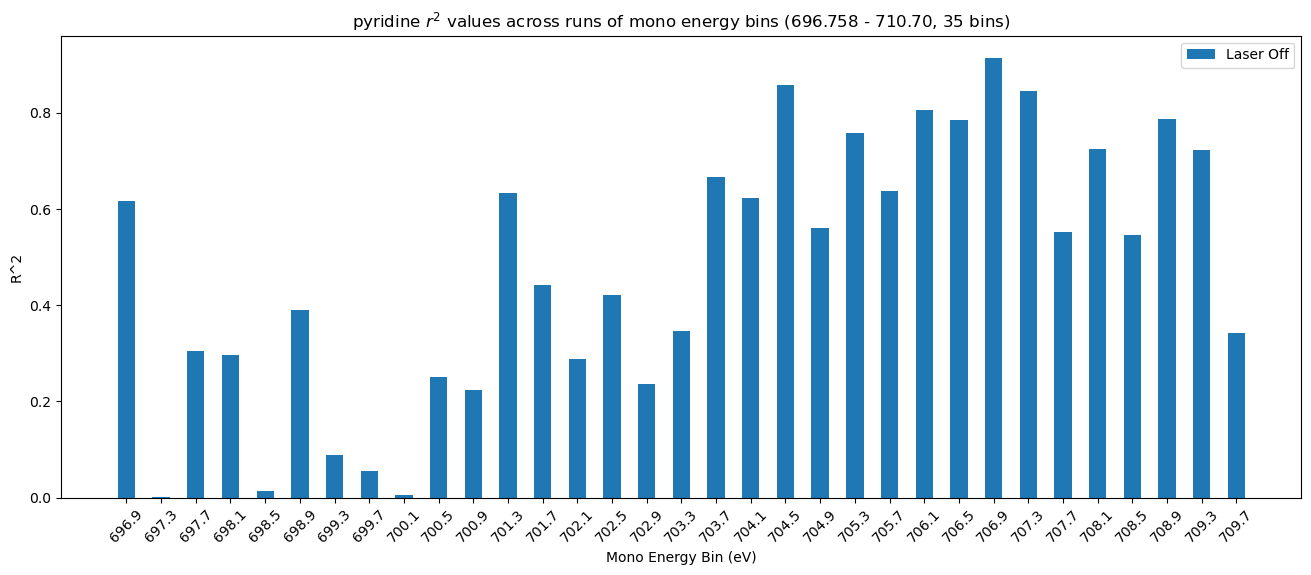

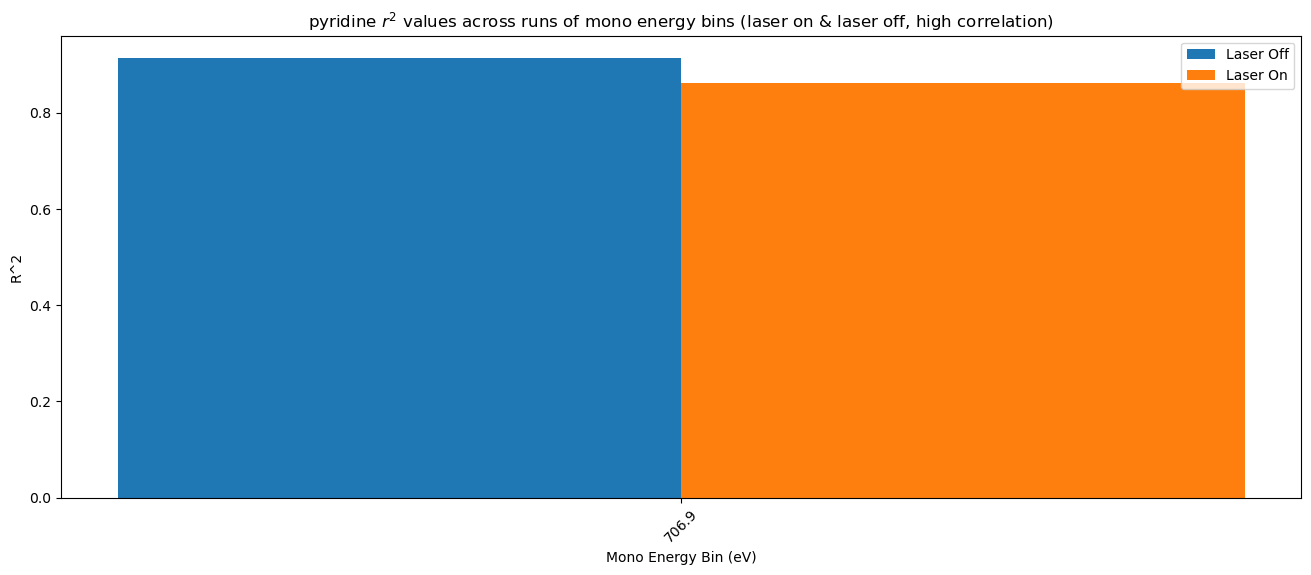

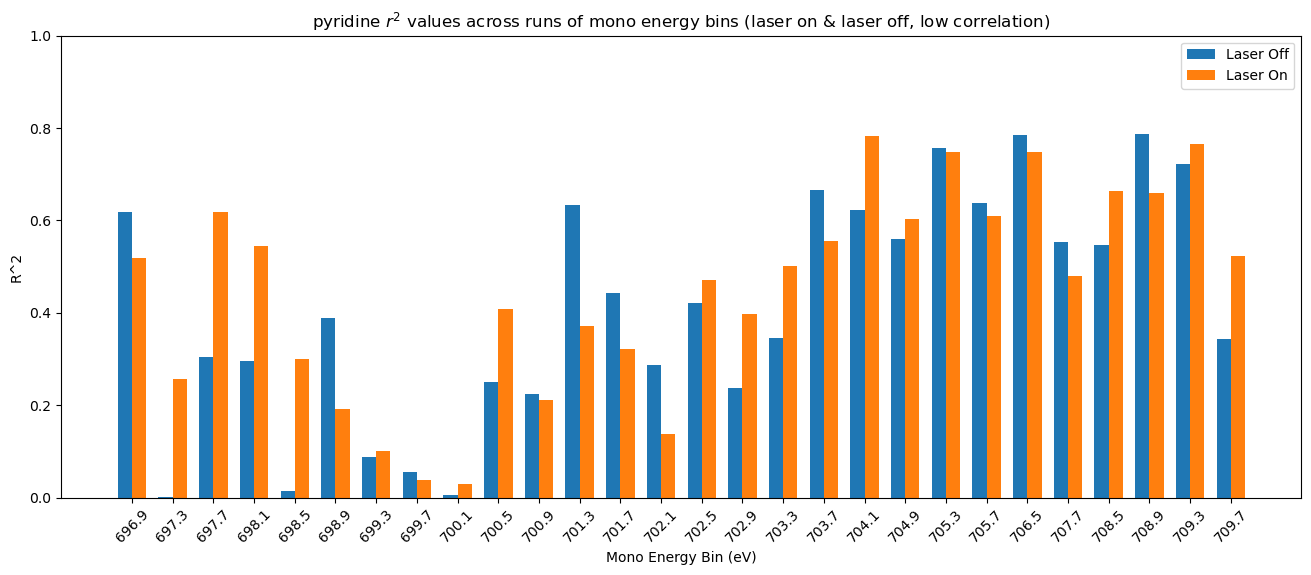

In [75]:
# loop through all bins

pyridine_off_r2 = []
pyridine_on_r2 = []
pyridine_off_f_r2 = []
pyridine_on_f_r2 = []

for i in range(len(scanvar)):

    
    x1 = pyridine_i0_off[:,i]
    y1 = pyridine_sos_off[:,i]
    
    x2 = pyridine_i0_on[:,i]
    y2 = pyridine_sos_on[:,i]
    
    x3 = pyridine_i0_off_f[:,i]
    y3 = pyridine_sos_off_f[:,i]
    
    x4 = pyridine_i0_on_f[:,i]
    y4 = pyridine_sos_on_f[:,i]
    
    # find the r^2 for each bin
    m1, b1, r1, p1, std_err1 = st.linregress(x1, y1)
    m2, b2, r2, p2, std_err2 = st.linregress(x2, y2)
    m3, b3, r3, p3, std_err3 = st.linregress(x3, y3)
    m4, b4, r4, p4, std_err4 = st.linregress(x4, y4)
    
    
    pyridine_off_r2.append(r1**2)
    pyridine_on_r2.append(r2**2)
    pyridine_off_f_r2.append(r3**2)
    pyridine_on_f_r2.append(r4**2)
    




# pinpoiint all the runs that have r^2 values over 0.8 for both laser on and laser off
mask_high_r2 = (np.array(pyridine_off_r2) > 0.8) & (np.array(pyridine_on_r2) > 0.8)
mask_low_r2 = (np.array(pyridine_off_r2) < 0.8) & (np.array(pyridine_on_r2) < 0.8)

plt.figure(figsize = (16,6))
x_bar = np.arange(len(scanvar))
width = 0.5
plt.bar(x_bar, np.array(pyridine_off_r2), width, label = "Laser Off")
# plt.bar(x_bar + width/2, np.array(pyridine_on_r2), width, label = "Laser On")
plt.xticks(x_bar, labels = [f'{x:.1f}' for x in np.array(scanvar)], rotation = 45)
plt.xlabel('Mono Energy Bin (eV)')
plt.ylabel('R^2')
plt.title('pyridine $r^2$ values across runs of mono energy bins (696.758 - 710.70, 35 bins)')
# plt.xlim(-1, len(scanvar)-17.5)
plt.legend()

plt.figure(figsize=(16,6))

x_bar = np.arange(sum(mask_high_r2))
width = 0.35
plt.bar(x_bar - width/2, np.array(pyridine_off_r2)[mask_high_r2], width, label = "Laser Off")
plt.bar(x_bar + width/2, np.array(pyridine_on_r2)[mask_high_r2], width, label = "Laser On")
# plt.bar(x_bar - width/2, pyridine_off_f_r2, width/2, label = "Laser Off Filtered", alpha = 0.5)
# plt.bar(x_bar + width/2, pyridine_on_f_r2, width/2, label = "Laser On Filtered", alpha = 0.5)
plt.xticks(x_bar, labels = [f'{x:.1f}' for x in np.array(scanvar)[mask_high_r2]], rotation = 45)
plt.xlabel('Mono Energy Bin (eV)')
plt.ylabel('R^2')
plt.title('pyridine $r^2$ values across runs of mono energy bins (laser on & laser off, high correlation)')
# plt.xlim(-1, len(scanvar)-17.5)
plt.legend()


plt.figure(figsize=(16,6))
x_bar = np.arange(sum(mask_low_r2))
width = 0.35
plt.bar(x_bar - width/2, np.array(pyridine_off_r2)[mask_low_r2], width, label = "Laser Off")
plt.bar(x_bar + width/2, np.array(pyridine_on_r2)[mask_low_r2], width, label = "Laser On")
# plt.bar(x_bar - width/2, pyridine_off_f_r2, width/2, label = "Laser Off Filtered", alpha = 0.5)
# plt.bar(x_bar + width/2, pyridine_on_f_r2, width/2, label = "Laser On Filtered", alpha = 0.5)
plt.xticks(x_bar, labels = [f'{x:.1f}' for x in np.array(scanvar)[mask_low_r2]], rotation = 45)
plt.xlabel('Mono Energy Bin (eV)')
plt.ylabel('R^2')
plt.title('pyridine $r^2$ values across runs of mono energy bins (laser on & laser off, low correlation)')
# plt.xlim(-1, len(scanvar)-17.5)
plt.ylim(0,1)
plt.legend()
plt.show()

#### Start writing a function where I can just conduct all of my run to run comparisons. Basically reduces all the runs and stores the values in lists that I can then call

In [ ]:
def run_to_run_analysis(runs):
    """
    Runs the reduce function on a list of runs and returns run to run values that I can use
    
    params:
         runs: list of the desired runs to reduce
        
    returns:
        dict with keys:
            pyridine_sos_on, pyridine_sos_off, pyridine_i0_on, pyridine_i0_off,
            pyridine_sos_on_f, pyridine_sos_off_f, pyridine_i0_on_f, pyridine_i0_off_f
    """
    
    sos_on_raw = []
    sos_off_raw = []
    i0_on_raw = []
    i0_off_raw = []
    
        

In [28]:
methoxy_runs = [178, 179, 180, 181, 182, 184, 185, 186, 188, 236, 237, 238, 249, 250, 252]
methoxy_selected_runs = [178,179,180, 181, 182, 184, 185, 186, 188, 236, 249, 250]
methoxy_selected_runs_v2 = [179,180, 181, 182, 184, 185,186, 237, 238, 249, 250]
    
    
methoxy_early_runs = [178, 179, 180, 181]
methoxy_middle_runs = [182, 185, 188, 236, 237, 238, 249, 250]
methoxy_late_runs = [184, 186, 252]
# unfiltered
methoxy_sos_on = []
methoxy_sos_off = []

methoxy_i0_on = []
methoxy_i0_off = []




# filtered, all the filtered keys just add a "f" at the end
methoxy_sos_on_f = []
methoxy_sos_off_f = []
methoxy_i0_on_f = []
methoxy_i0_off_f = []


# processed values that are sos but not raw, right now just the ground state spectrum should be enough, just comparing the shifts
methoxy_sos_off_norm = []
methoxy_sos_on_norm = []



early_shift = -0.03
late_shift = 0.03

for i in methoxy_early_runs:
    r = reduce(i, sigma_tresh=2, num_bins = 33, bin_start = 696.9 + early_shift, bin_end = 710.1 + early_shift)
    methoxy_sos_on.append(r['adu_total_on'])
    methoxy_sos_off.append(r['adu_total_off'])
    methoxy_i0_on.append(r['i0_sum_on'])
    methoxy_i0_off.append(r['i0_sum_off'])
    
    
    
    methoxy_sos_on_f.append(r['adu_total_on_filtered'])
    methoxy_sos_off_f.append(r['adu_total_off_filtered'])
    methoxy_i0_on_f.append(r['i0_sum_on_filtered'])
    methoxy_i0_off_f.append(r['i0_sum_off_filtered'])
    
    methoxy_sos_off_norm.append(r['PFY_off_sosadu'])
    methoxy_sos_on_norm.append(r['PFY_on_sosadu'])
    
for i in methoxy_middle_runs:
    r = reduce(i, sigma_tresh=2, num_bins = 33, bin_start = 696.9 , bin_end = 710.1 )
    methoxy_sos_on.append(r['adu_total_on'])
    methoxy_sos_off.append(r['adu_total_off'])
    methoxy_i0_on.append(r['i0_sum_on'])
    methoxy_i0_off.append(r['i0_sum_off'])
    
    
    
    methoxy_sos_on_f.append(r['adu_total_on_filtered'])
    methoxy_sos_off_f.append(r['adu_total_off_filtered'])
    methoxy_i0_on_f.append(r['i0_sum_on_filtered'])
    methoxy_i0_off_f.append(r['i0_sum_off_filtered'])
    
    methoxy_sos_off_norm.append(r['PFY_off_sosadu'])
    methoxy_sos_on_norm.append(r['PFY_on_sosadu'])

for i in methoxy_late_runs:
    r = reduce(i, sigma_tresh=2, num_bins = 33, bin_start = 696.9+late_shift , bin_end = 710.1+late_shift )
    methoxy_sos_on.append(r['adu_total_on'])
    methoxy_sos_off.append(r['adu_total_off'])
    methoxy_i0_on.append(r['i0_sum_on'])
    methoxy_i0_off.append(r['i0_sum_off'])
    
    
    
    methoxy_sos_on_f.append(r['adu_total_on_filtered'])
    methoxy_sos_off_f.append(r['adu_total_off_filtered'])
    methoxy_i0_on_f.append(r['i0_sum_on_filtered'])
    methoxy_i0_off_f.append(r['i0_sum_off_filtered'])
    
    methoxy_sos_off_norm.append(r['PFY_off_sosadu'])
    methoxy_sos_on_norm.append(r['PFY_on_sosadu'])


methoxy_sos_on = np.array(methoxy_sos_on)
methoxy_sos_off = np.array(methoxy_sos_off)
methoxy_i0_on = np.array(methoxy_i0_on) 
methoxy_i0_off = np.array(methoxy_i0_off)

methoxy_sos_on_f = np.array(methoxy_sos_on_f)
methoxy_sos_off_f = np.array(methoxy_sos_off_f)
methoxy_i0_on_f = np.array(methoxy_i0_on_f)
methoxy_i0_off_f = np.array(methoxy_i0_off_f)

methoxy_sos_off_norm = np.array(methoxy_sos_off_norm)
methoxy_sos_on_norm = np.array(methoxy_sos_on_norm)

  h5 read: 0.8s
  dropped 822 shots below 10% of median I0 (3.669e+06)
  processing: 2.4s
run 178: 3.1s, peak RSS 6.0 GB
  h5 read: 0.8s
  processing: 2.5s
run 179: 3.3s, peak RSS 6.0 GB
  h5 read: 0.7s
  processing: 2.3s
run 180: 3.1s, peak RSS 6.0 GB
  h5 read: 0.8s
  processing: 2.3s
run 181: 3.1s, peak RSS 6.0 GB
  h5 read: 0.7s
  processing: 2.3s
run 182: 3.0s, peak RSS 6.0 GB
  h5 read: 0.7s
  processing: 2.3s
run 185: 3.0s, peak RSS 6.0 GB
  h5 read: 0.7s
  processing: 2.3s
run 188: 3.0s, peak RSS 6.0 GB
  h5 read: 0.7s
  dropped 494 shots below 10% of median I0 (3.850e+06)
  processing: 2.3s
run 236: 3.0s, peak RSS 6.0 GB
  h5 read: 0.7s
  dropped 486 shots below 10% of median I0 (3.616e+06)
  processing: 2.3s
run 237: 3.1s, peak RSS 6.0 GB
  h5 read: 0.8s
  dropped 61 shots below 10% of median I0 (3.820e+06)
  processing: 2.4s
run 238: 3.2s, peak RSS 6.0 GB
  h5 read: 0.9s
  dropped 129 shots below 10% of median I0 (4.123e+06)
  processing: 2.3s
run 249: 3.3s, peak RSS 6.0 GB


[179, 180, 181, 182, 184, 185, 186, 237, 238, 249, 250]


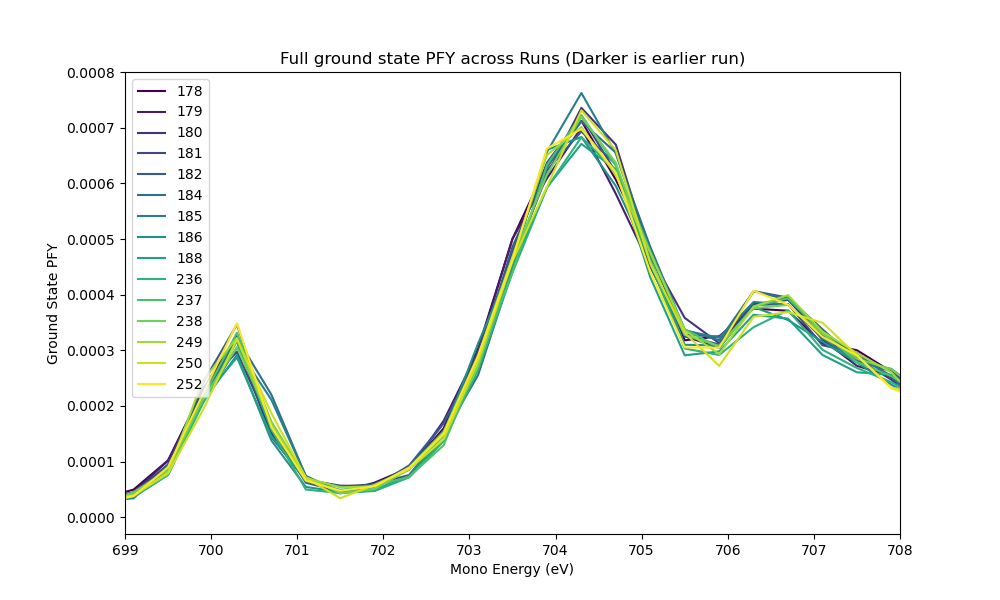

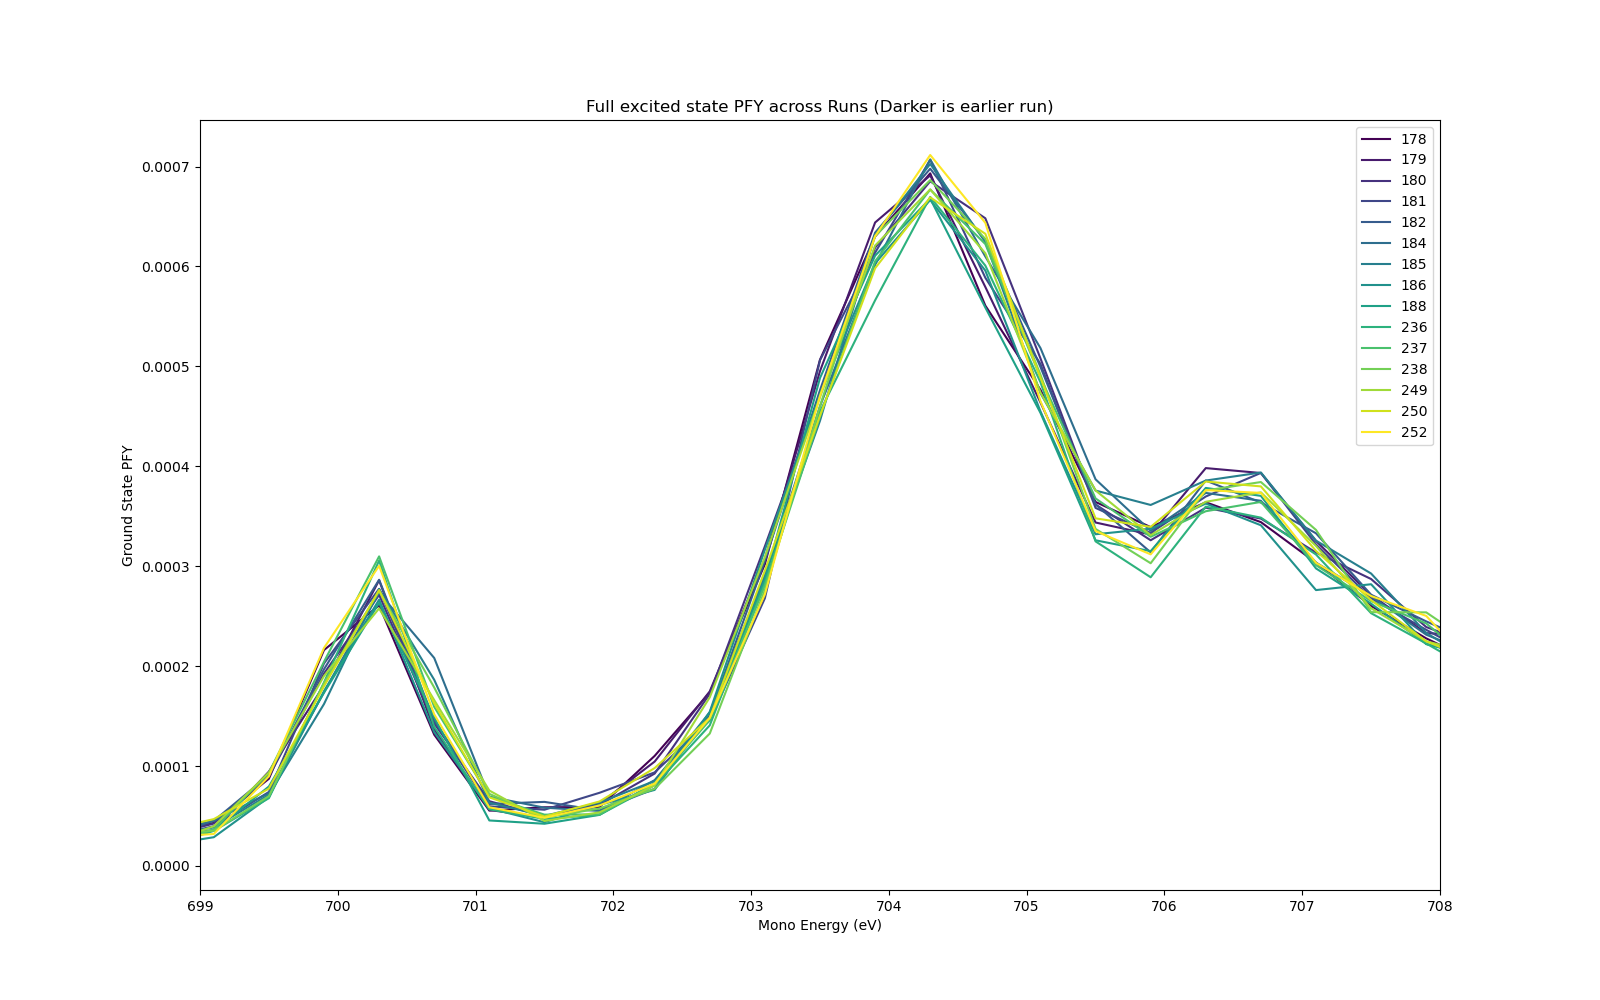

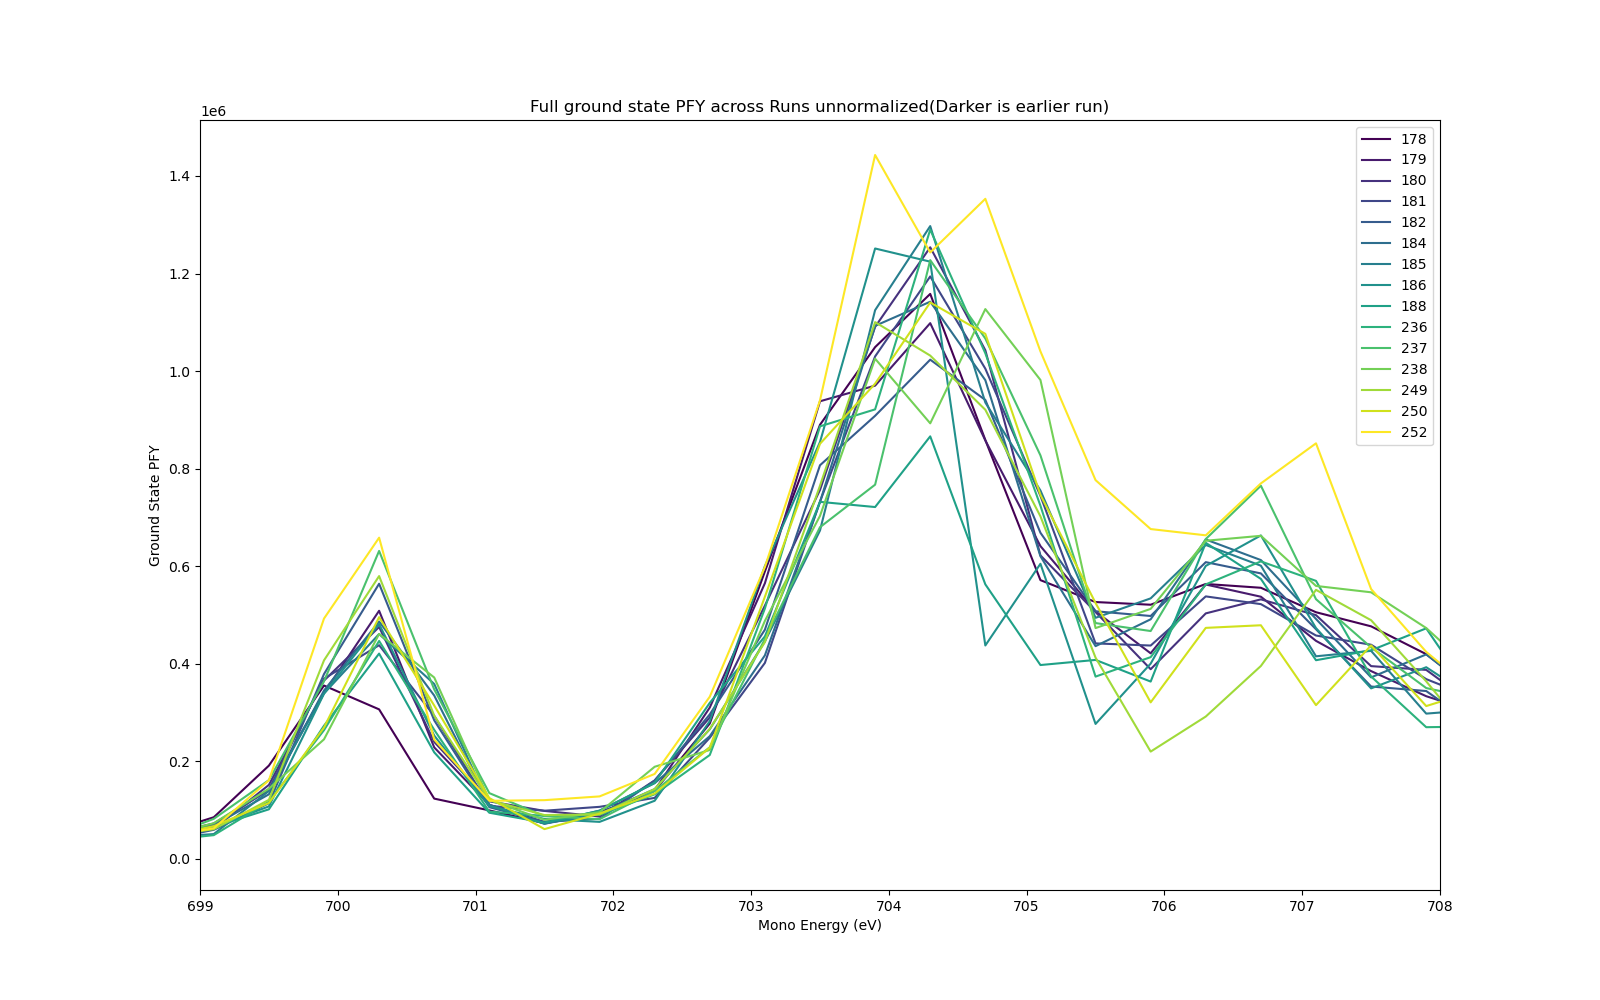

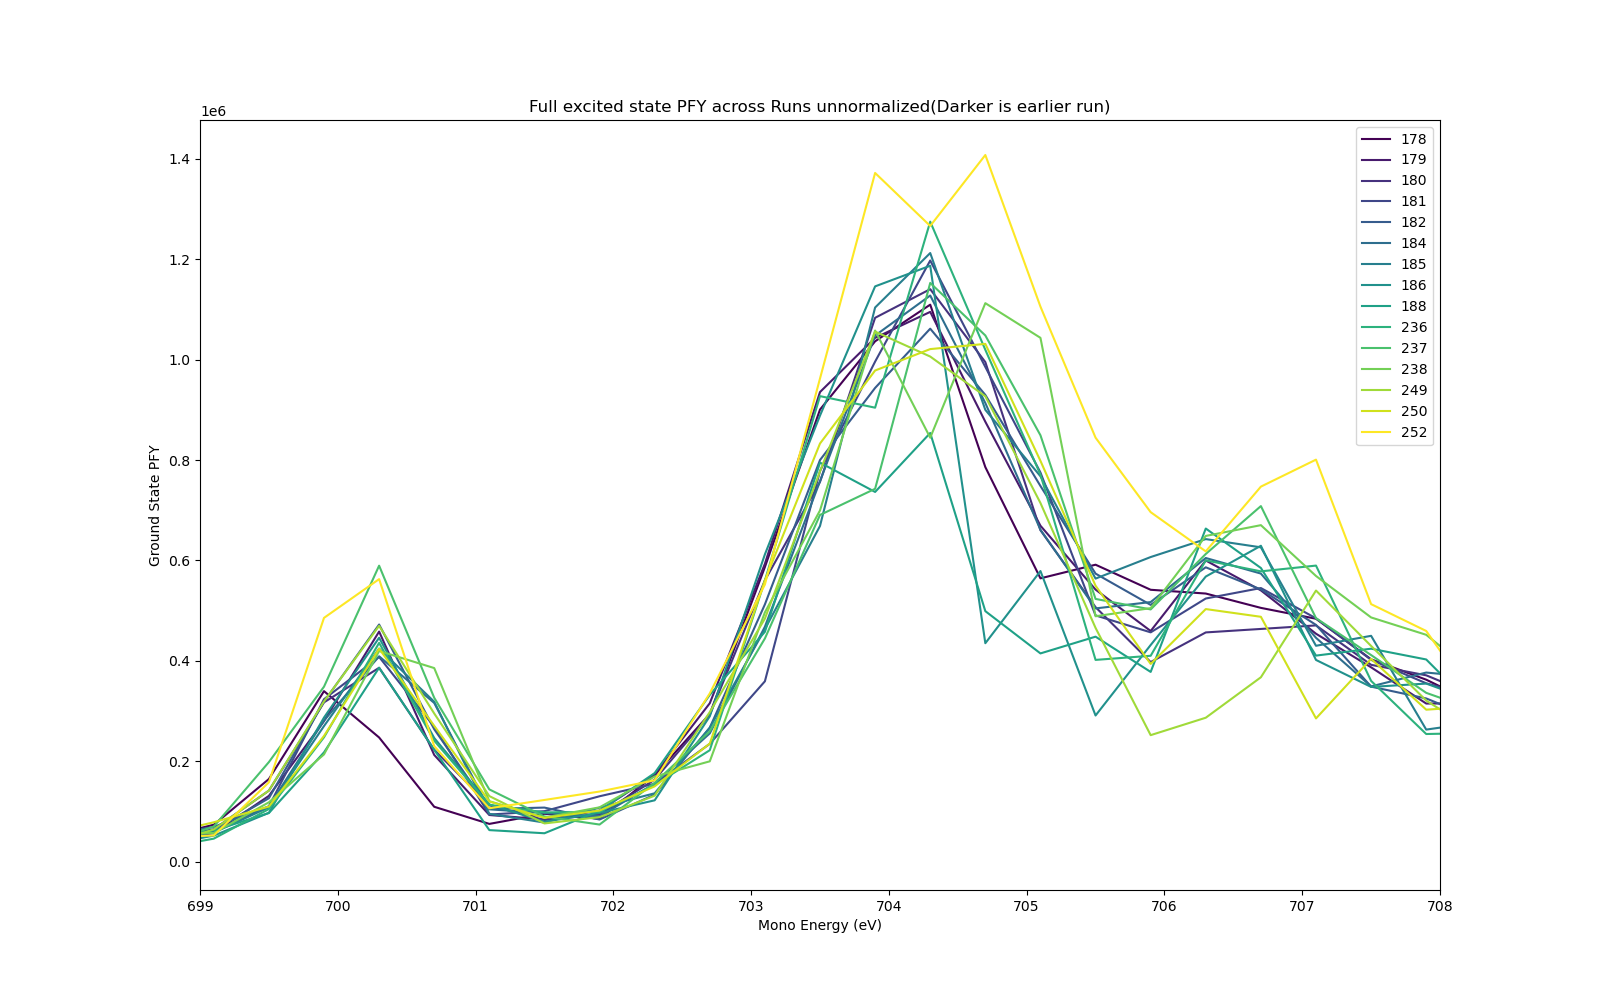

In [29]:
color_gradient = plt.cm.viridis(np.linspace(0,1.0,len(methoxy_runs)))
print(methoxy_selected_runs_v2)

plt.figure(figsize=(10, 6))
for i,_ in enumerate(methoxy_sos_off):
    plt.plot(scanvar, methoxy_sos_off_norm[i], color=color_gradient[i], label = f'{methoxy_runs[i]}')
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Ground State PFY')
plt.title("Full ground state PFY across Runs (Darker is earlier run)")
plt.xlim([699, 708])
#plt.ylim([0, 0.0008])
plt.legend()
plt.show()

plt.figure(figsize=(16, 10))
for i,_ in enumerate(methoxy_sos_on):
    plt.plot(scanvar, methoxy_sos_on_norm[i], color=color_gradient[i], label = f'{methoxy_runs[i]}')
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Ground State PFY')
plt.title("Full excited state PFY across Runs (Darker is earlier run)")
plt.xlim([699, 708])
#plt.ylim([0, 0.0008])
plt.legend()
plt.show()

plt.figure(figsize=(16, 10))
for i,_ in enumerate(methoxy_sos_off):
    plt.plot(scanvar, methoxy_sos_off[i], color=color_gradient[i], label = f'{methoxy_runs[i]}')
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Ground State PFY')
plt.title("Full ground state PFY across Runs unnormalized(Darker is earlier run)")
plt.xlim([699, 708])
#plt.ylim([0, 0.0008])
plt.legend()
plt.show()

plt.figure(figsize=(16, 10))
for i,_ in enumerate(methoxy_sos_on):
    plt.plot(scanvar, methoxy_sos_on[i], color=color_gradient[i], label = f'{methoxy_runs[i]}')
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Ground State PFY')
plt.title("Full excited state PFY across Runs unnormalized(Darker is earlier run)")
plt.xlim([699, 708])
#plt.ylim([0, 0.0008])
plt.legend()
plt.show()

# methoxy_selected_runs_v2 = [179,180, 181, 182, 184, 185,186, 237, 238, 249, 250]


(13, 33)
(13, 33)


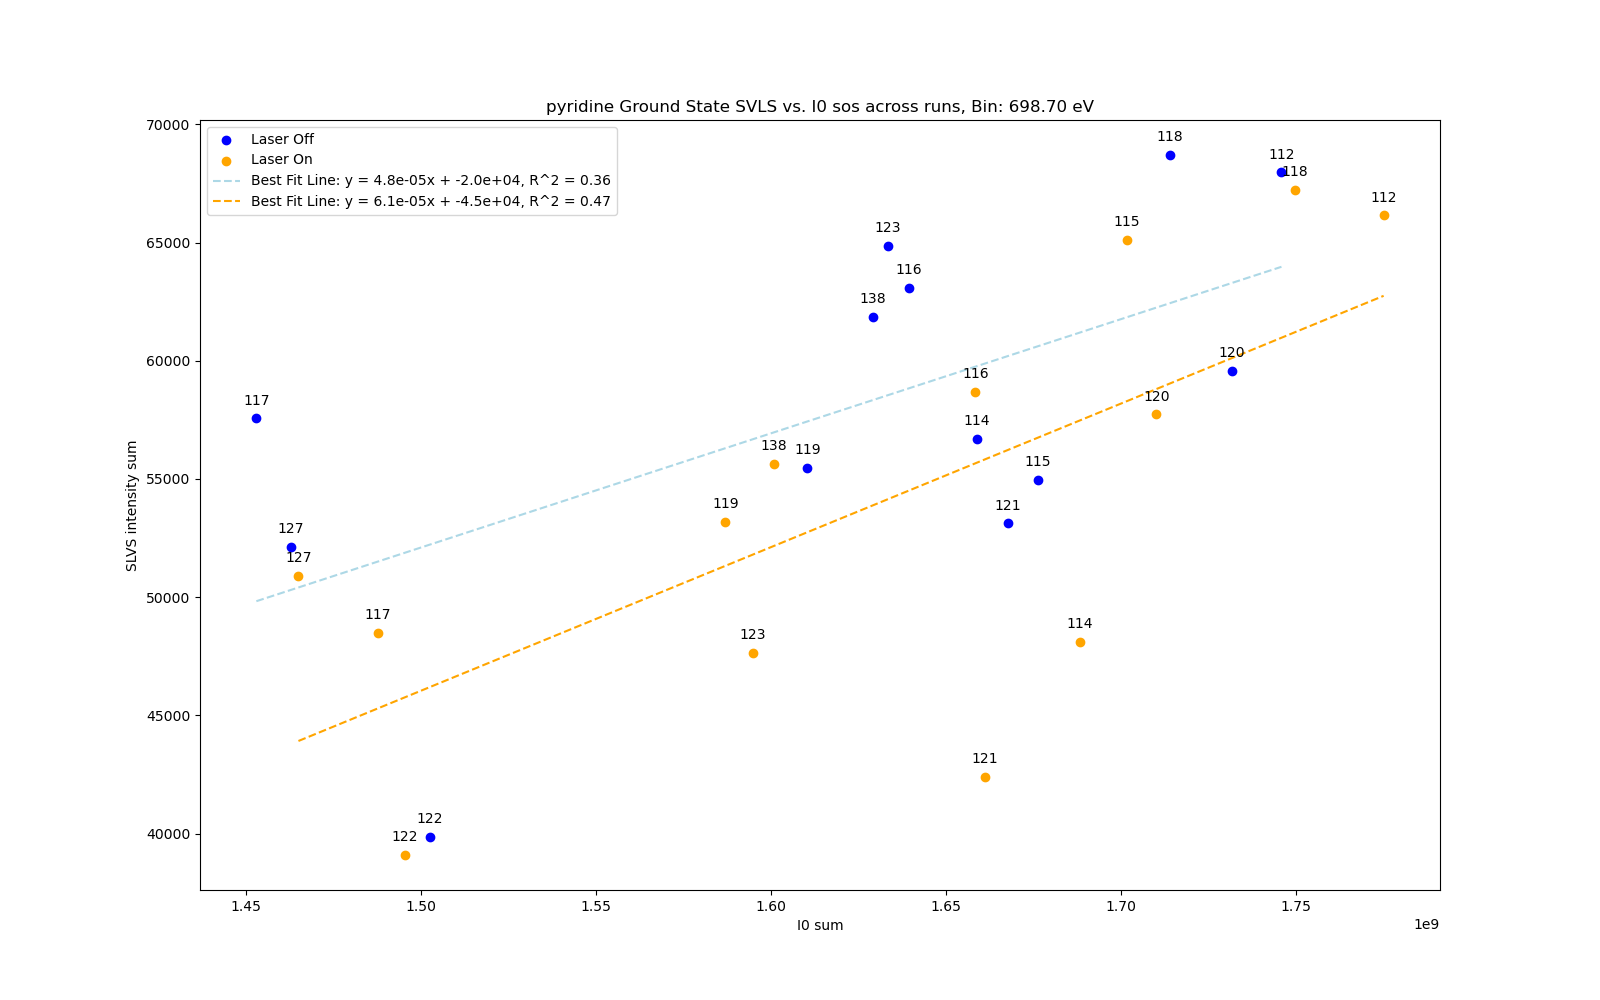

IndexError: boolean index did not match indexed array along dimension 0; dimension is 17 but corresponding boolean dimension is 13

In [246]:
print(pyridine_sos_on.shape)
print(pyridine_i0_on.shape)

bin_num = 5


fig, ax = plt.subplots(1, 1, figsize=(16, 10))
x1 = pyridine_i0_off[:,bin_num]
y1 = pyridine_sos_off[:,bin_num]

x2 = pyridine_i0_on[:,bin_num]
y2 = pyridine_sos_on[:,bin_num]

#ax.scatter(pyridine_i0_on[:,1], pyridine_sos_on[:,1], color='blue', label='Laser On')
ax.scatter(x1, y1, color='blue', label = 'Laser Off')
ax.scatter(x2, y2, color='orange', label = 'Laser On')

# fit a best fit line to see the correlation
m1, b1, r1_value, p1_value, std_err1 = st.linregress(x1,y1)

m2, b2, r2_value, p2_value, std_err2 = st.linregress(x2,y2)



# plot the best fit line 
x1_fit = np.linspace(np.min(x1), np.max(x1), 100)
y1_fit = m1*x1_fit + b1
ax.plot(x1_fit, y1_fit, color = 'lightblue', linestyle = '--', label = f'Best Fit Line: y = {m1:.1e}x + {b1:.1e}, R^2 = {r1_value **2:.2f}')

x2_fit = np.linspace(np.min(x2), np.max(x2), 100)
y2_fit = m2*x2_fit + b2
ax.plot(x2_fit, y2_fit, color = 'orange', linestyle = '--', label = f'Best Fit Line: y = {m2:.1e}x + {b2:.1e}, R^2 = {r2_value **2:.2f}')

for xi,yi, label in zip(x1, y1, pyridine_runs):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(0,10), ha='center')
for xi,yi, label in zip(x2, y2, pyridine_runs):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(0,10), ha='center')
ax.set_xlabel('I0 sum')
ax.set_ylabel('SLVS intensity sum')
ax.set_title(f'pyridine Ground State SVLS vs. I0 sos across runs, Bin: {scanvar[bin_num]:.2f} eV')
ax.legend()
plt.show()


n_runs, n_bins = pyridine_sos_on.shape

keep_on  = np.zeros((n_runs, n_bins), dtype=bool)
keep_off = np.zeros((n_runs, n_bins), dtype=bool)
pct_on   = np.zeros(n_bins)
pct_off  = np.zeros(n_bins)

for i in range(n_bins):
    m_on,  *_, info_on  = filter_correlation(pyridine_i0_on[:, i],
                                             pyridine_sos_on[:, i],  sigma_thresh=2, trim_k = 10, verbose=False)
    m_off, *_, info_off = filter_correlation(pyridine_i0_off[:, i],
                                             pyridine_sos_off[:, i], sigma_thresh = 2, trim_k = 10, verbose=False)
    keep_on[:, i],  pct_on[i]  = m_on,  info_on['pct_dropped']
    keep_off[:, i], pct_off[i] = m_off, info_off['pct_dropped']

# blanked copies for plotting / nan-aware reduction
pyridine_sos_on_kept = [pyridine_sos_on[keep_on[:, i], i] for i in range(n_bins)]
pyridine_i0_on_kept  = [pyridine_i0_on[keep_on[:, i], i]  for i in range(n_bins)]
pyridine_sos_off_kept = [pyridine_sos_off[keep_off[:, i], i] for i in range(n_bins)]
pyridine_i0_off_kept  = [pyridine_i0_off[keep_off[:, i], i]  for i in range(n_bins)]



# also store the runs with the same mask
pyridine_runs = np.asarray(pyridine_runs)   # so boolean indexing works

pyridine_runs_on_kept  = [pyridine_runs[keep_on[:, i]]  for i in range(n_bins)]
pyridine_runs_off_kept = [pyridine_runs[keep_off[:, i]] for i in range(n_bins)]


############################ PLOTTING ################################


fig, ax = plt.subplots(1, 1, figsize=(16, 10))
x1 = pyridine_i0_off_kept[:][bin_num]
y1 = pyridine_sos_off_kept[:][bin_num]

x2 = pyridine_i0_on_kept[:][bin_num]
y2 = pyridine_sos_on_kept[:][bin_num]

lab1   = pyridine_runs_off_kept[bin_num]
lab2   = pyridine_runs_on_kept[bin_num]



#ax.scatter(pyridine_i0_on[:,1], pyridine_sos_on[:,1], color='blue', label='Laser On')
ax.scatter(x1, y1, color='blue', label = 'Laser Off')
ax.scatter(x2, y2, color='orange', label = 'Laser On')

# fit a best fit line to see the correlation
m1, b1, r1_value, p1_value, std_err1 = st.linregress(x1,y1)

m2, b2, r2_value, p2_value, std_err2 = st.linregress(x2,y2)



# plot the best fit line 
x1_fit = np.linspace(np.min(x1), np.max(x1), 100)
y1_fit = m1*x1_fit + b1
ax.plot(x1_fit, y1_fit, color = 'lightblue', linestyle = '--', label = f'Best Fit Line: y = {m1:.1e}x + {b1:.1e}, R^2 = {r1_value **2:.2f}')

x2_fit = np.linspace(np.min(x2), np.max(x2), 100)
y2_fit = m2*x2_fit + b2
ax.plot(x2_fit, y2_fit, color = 'orange', linestyle = '--', label = f'Best Fit Line: y = {m2:.1e}x + {b2:.1e}, R^2 = {r2_value **2:.2f}')

for xi,yi, label in zip(x1, y1, lab1):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(0,10), ha='center')
for xi,yi, label in zip(x2, y2, lab2):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(0,10), ha='center')
ax.set_xlabel('I0 sum')
ax.set_ylabel('SLVS intensity sum')
ax.set_title(f'pyridine Ground State SVLS vs. I0 sos across runs, Bin: {scanvar[bin_num]:.2f} eV')
ax.legend(loc = 'lower right')
plt.show()

### try to run the correlation filters on these lol and see how the plots look afterwards

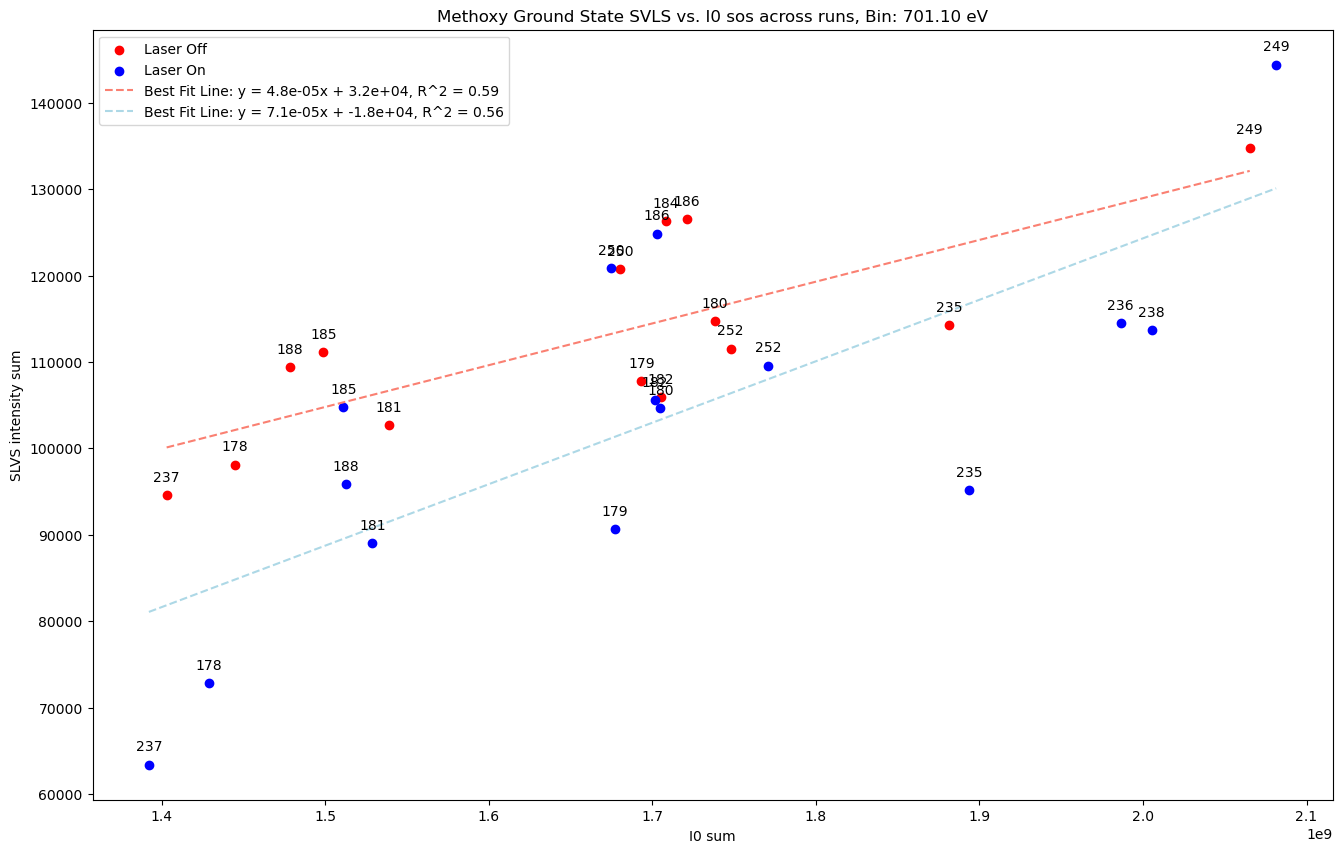

In [36]:
n_runs, n_bins = methoxy_sos_on.shape

keep_on  = np.zeros((n_runs, n_bins), dtype=bool)
keep_off = np.zeros((n_runs, n_bins), dtype=bool)
pct_on   = np.zeros(n_bins)
pct_off  = np.zeros(n_bins)

for i in range(n_bins):
    m_on,  *_, info_on  = filter_correlation(methoxy_i0_on[:, i],
                                             methoxy_sos_on[:, i],  sigma_thresh=1.8, trim_k = 10, verbose=False)
    m_off, *_, info_off = filter_correlation(methoxy_i0_off[:, i],
                                             methoxy_sos_off[:, i], sigma_thresh = 1.8, trim_k = 10, verbose=False)
    keep_on[:, i],  pct_on[i]  = m_on,  info_on['pct_dropped']
    keep_off[:, i], pct_off[i] = m_off, info_off['pct_dropped']

# blanked copies for plotting / nan-aware reduction
methoxy_sos_on_kept = [methoxy_sos_on[keep_on[:, i], i] for i in range(n_bins)]
methoxy_i0_on_kept  = [methoxy_i0_on[keep_on[:, i], i]  for i in range(n_bins)]
methoxy_sos_off_kept = [methoxy_sos_off[keep_off[:, i], i] for i in range(n_bins)]
methoxy_i0_off_kept  = [methoxy_i0_off[keep_off[:, i], i]  for i in range(n_bins)]



# also store the runs with the same mask
methoxy_runs = np.asarray(methoxy_runs)   # so boolean indexing works

methoxy_runs_on_kept  = [methoxy_runs[keep_on[:, i]]  for i in range(n_bins)]
methoxy_runs_off_kept = [methoxy_runs[keep_off[:, i]] for i in range(n_bins)]


############################ PLOTTING ################################


fig, ax = plt.subplots(1, 1, figsize=(16, 10))
x1 = methoxy_i0_off_kept[:][bin_num]
y1 = methoxy_sos_off_kept[:][bin_num]

x2 = methoxy_i0_on_kept[:][bin_num]
y2 = methoxy_sos_on_kept[:][bin_num]

lab1   = methoxy_runs_off_kept[bin_num]
lab2   = methoxy_runs_on_kept[bin_num]



#ax.scatter(methoxy_i0_on[:,1], methoxy_sos_on[:,1], color='blue', label='Laser On')
ax.scatter(x1, y1, color='red', label = 'Laser Off')
ax.scatter(x2, y2, color='blue', label = 'Laser On')

# fit a best fit line to see the correlation
m1, b1, r1_value, p1_value, std_err1 = st.linregress(x1,y1)

m2, b2, r2_value, p2_value, std_err2 = st.linregress(x2,y2)



# plot the best fit line 
x1_fit = np.linspace(np.min(x1), np.max(x1), 100)
y1_fit = m1*x1_fit + b1
ax.plot(x1_fit, y1_fit, color = 'salmon', linestyle = '--', label = f'Best Fit Line: y = {m1:.1e}x + {b1:.1e}, R^2 = {r1_value **2:.2f}')

x2_fit = np.linspace(np.min(x2), np.max(x2), 100)
y2_fit = m2*x2_fit + b2
ax.plot(x2_fit, y2_fit, color = 'lightblue', linestyle = '--', label = f'Best Fit Line: y = {m2:.1e}x + {b2:.1e}, R^2 = {r2_value **2:.2f}')

for xi,yi, label in zip(x1, y1, lab1):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(0,10), ha='center')
for xi,yi, label in zip(x2, y2, lab2):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(0,10), ha='center')
ax.set_xlabel('I0 sum')
ax.set_ylabel('SLVS intensity sum')
ax.set_title(f'Methoxy Ground State SVLS vs. I0 sos across runs, Bin: {scanvar[bin_num]:.2f} eV')
ax.legend()
plt.show()
    
    

### Check to see the residual across all of the bins of a particular run

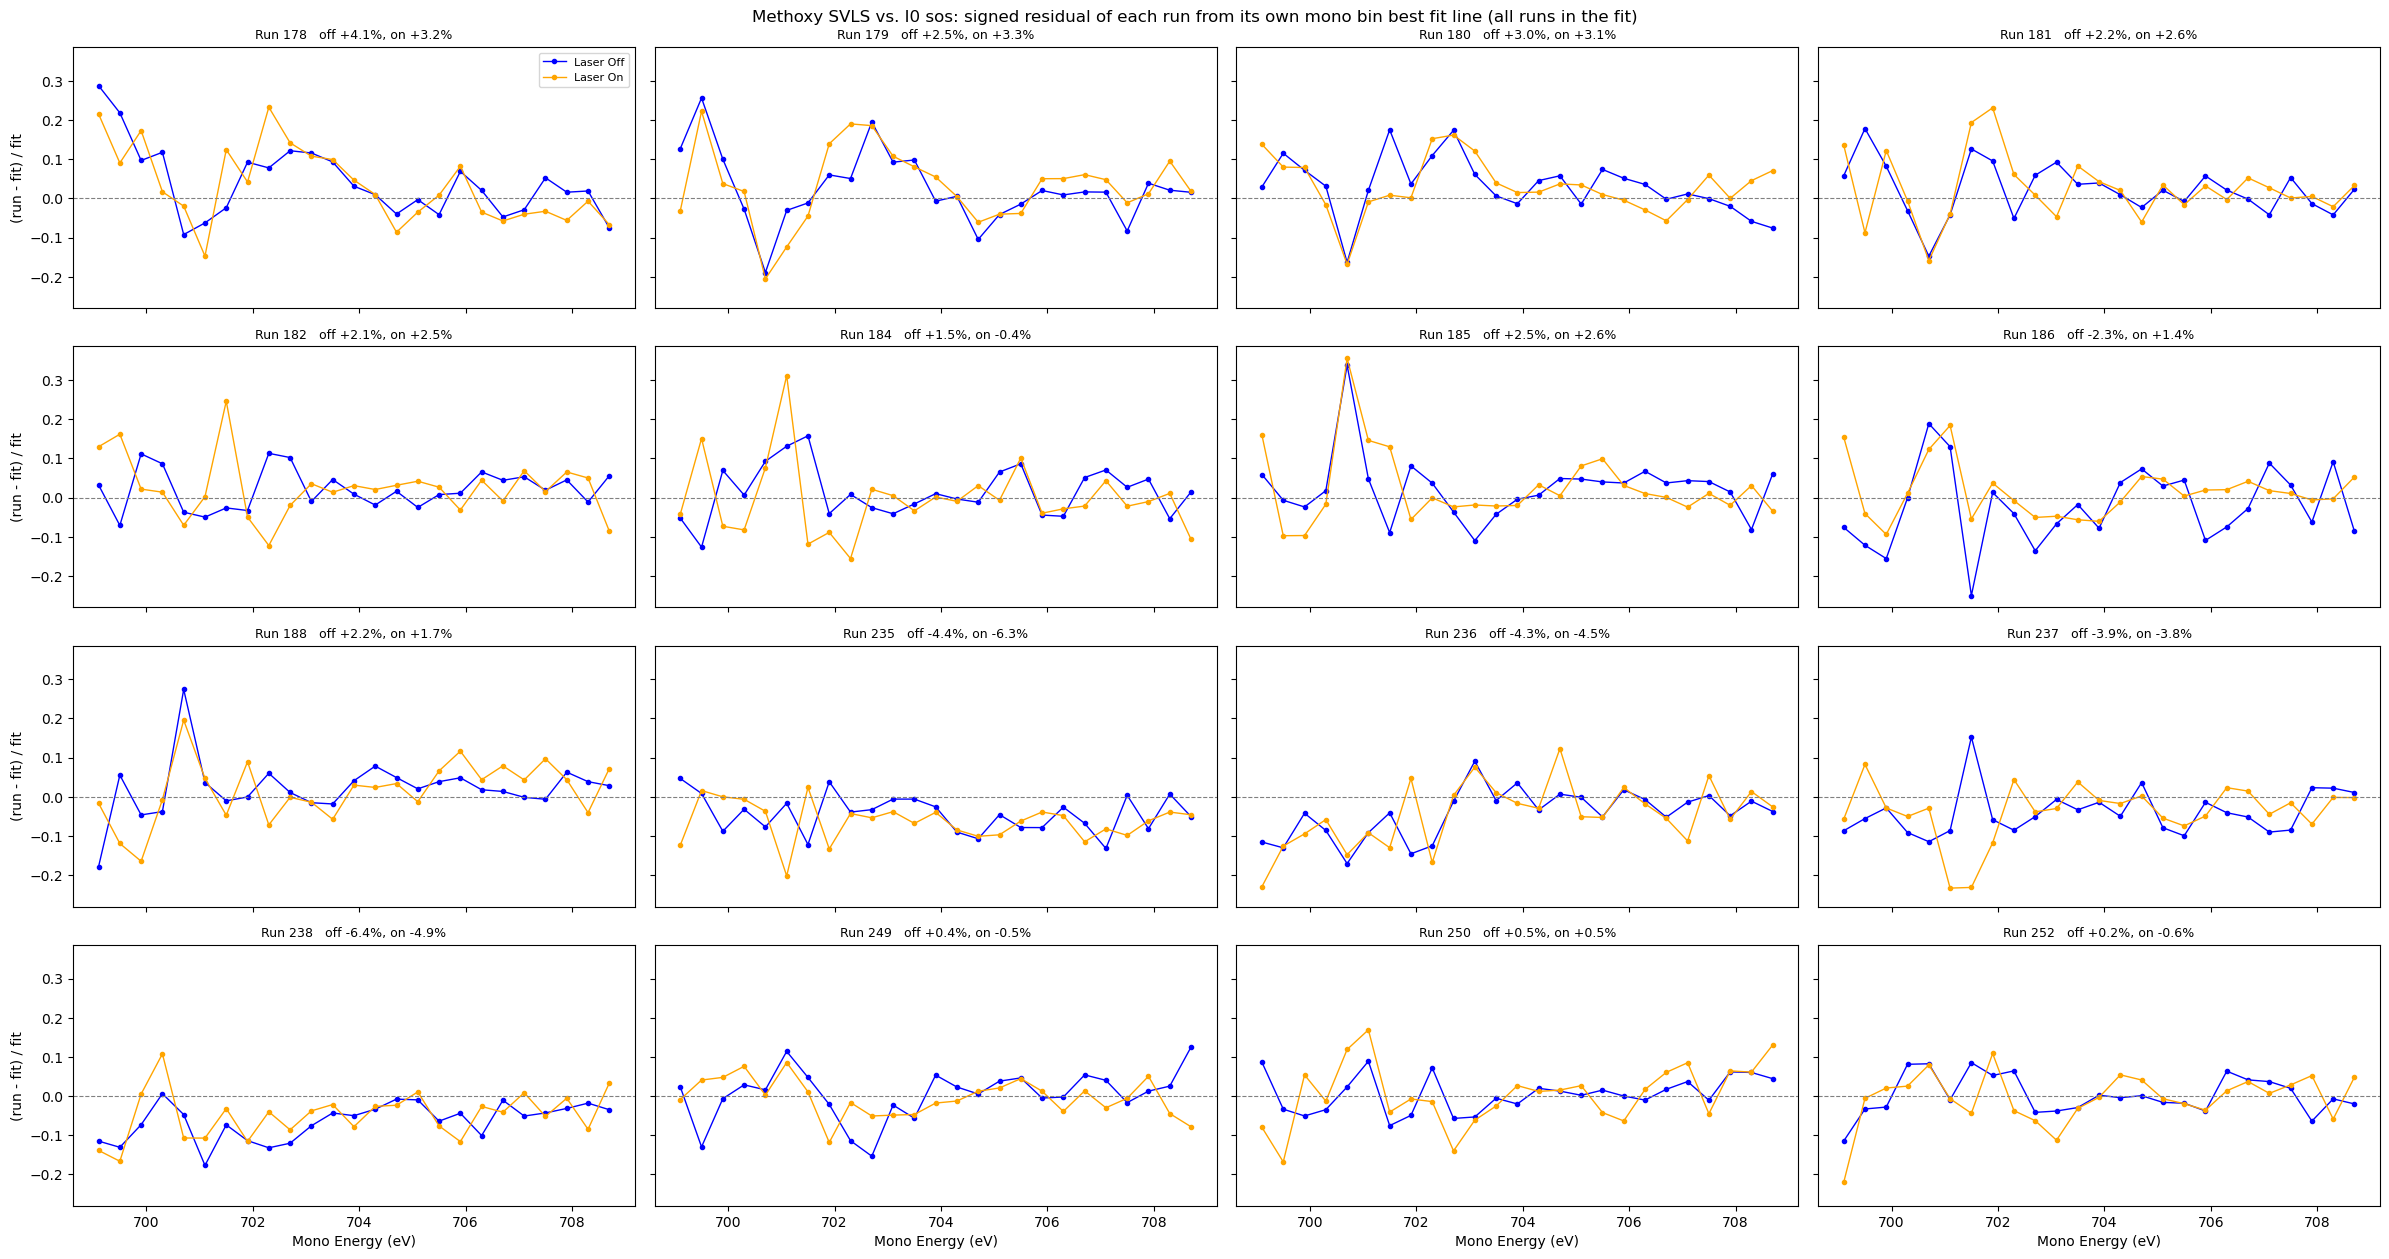

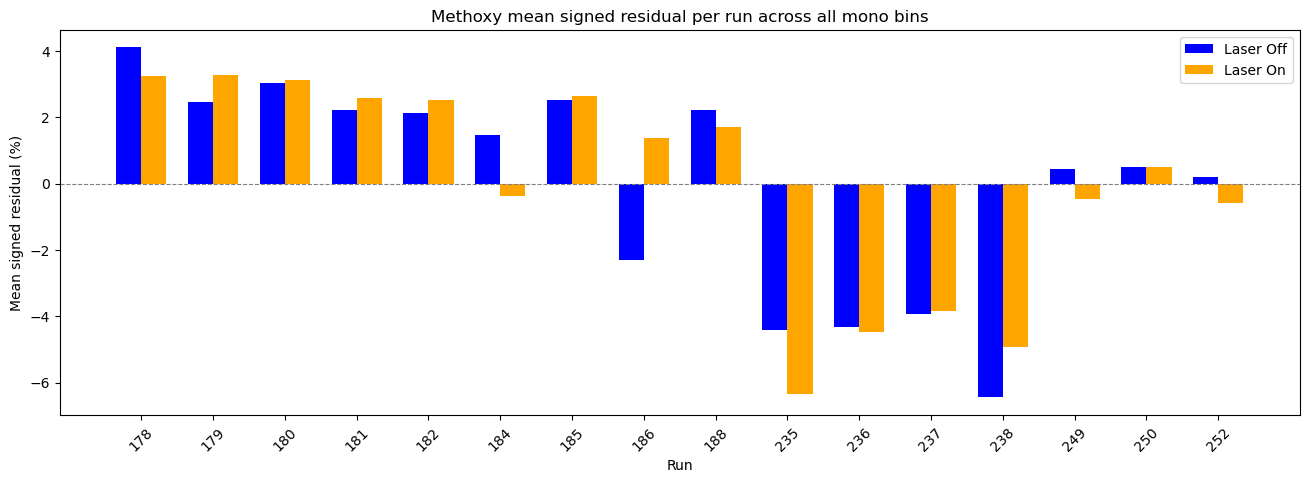

In [74]:
# find the residual of each run from its own mono bin's best fit line,
# using ALL the runs in the fit (i.e. before any run filtering)

n_runs, n_bins = methoxy_sos_on.shape


bin_range = [699,709]
relevant_bins = (scanvar > bin_range[0]) & (scanvar < bin_range[1])

methoxy_runs = np.asarray(methoxy_runs)

methoxy_res_off = np.zeros((n_runs, n_bins))
methoxy_res_on  = np.zeros((n_runs, n_bins))

# the same residual as a fraction of the fitted value, so that bins on the
# peak and bins in the baseline can be compared on one axis
methoxy_res_off_frac = np.zeros((n_runs, n_bins))
methoxy_res_on_frac  = np.zeros((n_runs, n_bins))

methoxy_off_r2 = np.zeros(n_bins)
methoxy_on_r2  = np.zeros(n_bins)

for i in range(n_bins):

    x1 = methoxy_i0_off[:,i]
    y1 = methoxy_sos_off[:,i]

    x2 = methoxy_i0_on[:,i]
    y2 = methoxy_sos_on[:,i]

    # fit a best fit line to see the correlation
    m1, b1, r1_value, p1_value, std_err1 = st.linregress(x1,y1)

    m2, b2, r2_value, p2_value, std_err2 = st.linregress(x2,y2)

    # what the best fit line predicts for each run's own I0
    y1_fit = m1*x1 + b1
    y2_fit = m2*x2 + b2

    # signed residual: positive means the run sits ABOVE the line, i.e. more
    # SVLS than its I0 says it should have
    methoxy_res_off[:,i] = y1 - y1_fit
    methoxy_res_on[:,i]  = y2 - y2_fit

    methoxy_res_off_frac[:,i] = (y1 - y1_fit) / y1_fit
    methoxy_res_on_frac[:,i]  = (y2 - y2_fit) / y2_fit

    methoxy_off_r2[i] = r1_value**2
    methoxy_on_r2[i]  = r2_value**2


############################ PLOTTING ################################

# one panel per run, each holding n_bins residuals across the mono scan
ncols = 4
nrows = int(np.ceil(n_runs/ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3.2*nrows),
                         sharex=True, sharey=True)
axes = np.atleast_2d(axes)

for j in range(n_runs):
    ax = axes[j // ncols][j % ncols]

    ax.plot(scanvar[relevant_bins], methoxy_res_off_frac[j][relevant_bins], color='blue', marker='o',
            ms=3, lw=1.0, label='Laser Off')
    ax.plot(scanvar[relevant_bins], methoxy_res_on_frac[j][relevant_bins], color='orange', marker='o',
            ms=3, lw=1.0, label='Laser On')
    ax.axhline(0, color='gray', linestyle='dashed', linewidth=0.8)

    # mean signed residual: a run that is genuinely off sits on one side
    mean_off = np.nanmean(methoxy_res_off_frac[j][relevant_bins])
    mean_on  = np.nanmean(methoxy_res_on_frac[j][relevant_bins])
    ax.set_title(f'Run {methoxy_runs[j]}   '
                 f'off {100*mean_off:+.1f}%, on {100*mean_on:+.1f}%',
                 fontsize=9)
    # ax.set_xticklabels([f'{x:.1f}' for x in scanvar], rotation = 45)
    # ax.set_xlim([700, 704.5])

    if j // ncols == nrows - 1:
        ax.set_xlabel('Mono Energy (eV)')
    if j % ncols == 0:
        ax.set_ylabel('(run - fit) / fit')

for j in range(n_runs, nrows*ncols):
    axes[j // ncols][j % ncols].axis('off')

axes[0][0].legend(fontsize=8, loc='upper right')
fig.suptitle('Methoxy SVLS vs. I0 sos: signed residual of each run from its '
             'own mono bin best fit line (all runs in the fit)')
fig.tight_layout()
plt.show()


# summary: mean signed residual per run, which is what actually separates a
# bad run from noise. Noise averages to zero across the scan, a bad run does not.
fig, ax = plt.subplots(1, 1, figsize=(16, 5))

x_bar = np.arange(n_runs)
width = 0.35
ax.bar(x_bar - width/2, 100*np.nanmean(methoxy_res_off_frac[:,relevant_bins], axis=1), width,
       color='blue', label='Laser Off')
ax.bar(x_bar + width/2, 100*np.nanmean(methoxy_res_on_frac[:,relevant_bins], axis=1), width,
       color='orange', label='Laser On')
ax.axhline(0, color='gray', linestyle='dashed', linewidth=0.8)
ax.set_xticks(x_bar)
ax.set_xticklabels([str(r) for r in methoxy_runs], rotation=45)
ax.set_xlabel('Run')
ax.set_ylabel('Mean signed residual (%)')
ax.set_title('Methoxy mean signed residual per run across all mono bins')
ax.legend()
plt.show()

#### Plot out the R^2 for all of the mono bins: we can do this for different values 

- no filter laser off
- no filter laser on
- filter laser off
- filter laser on


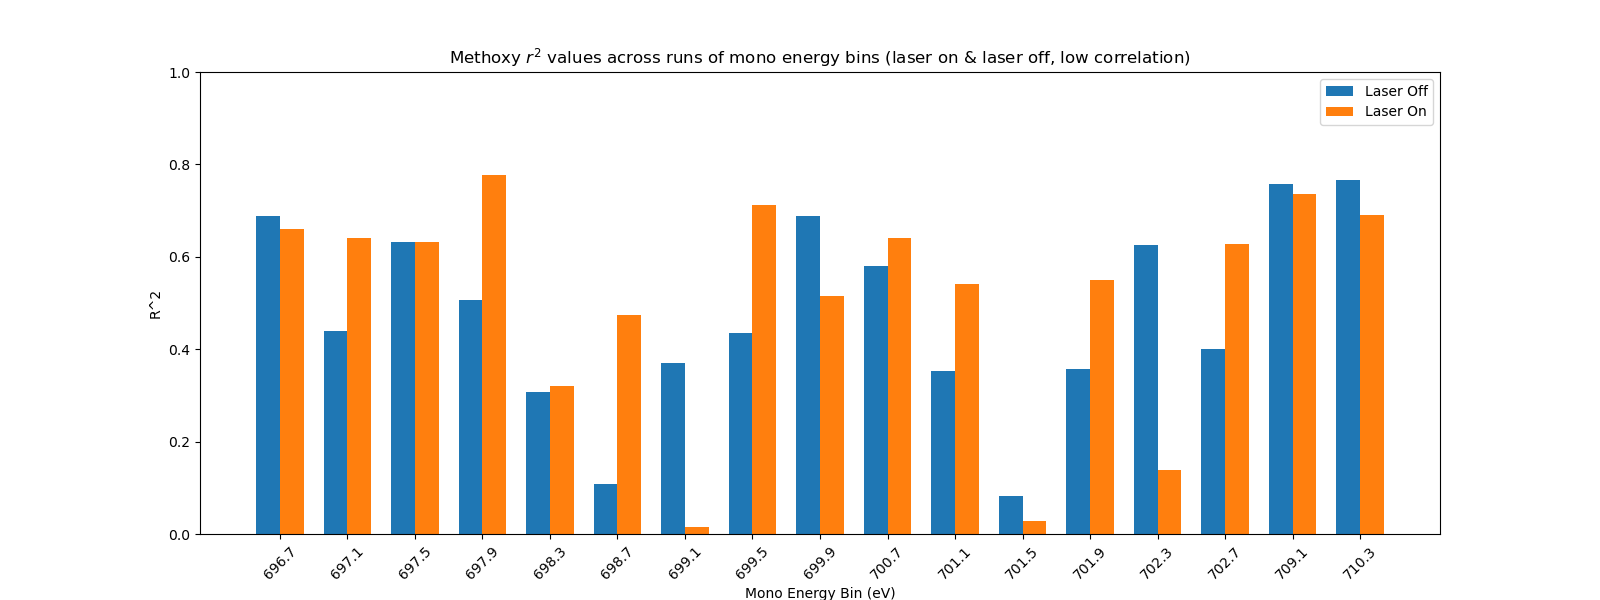

NameError: name 'methoxy_i0_off_kept' is not defined

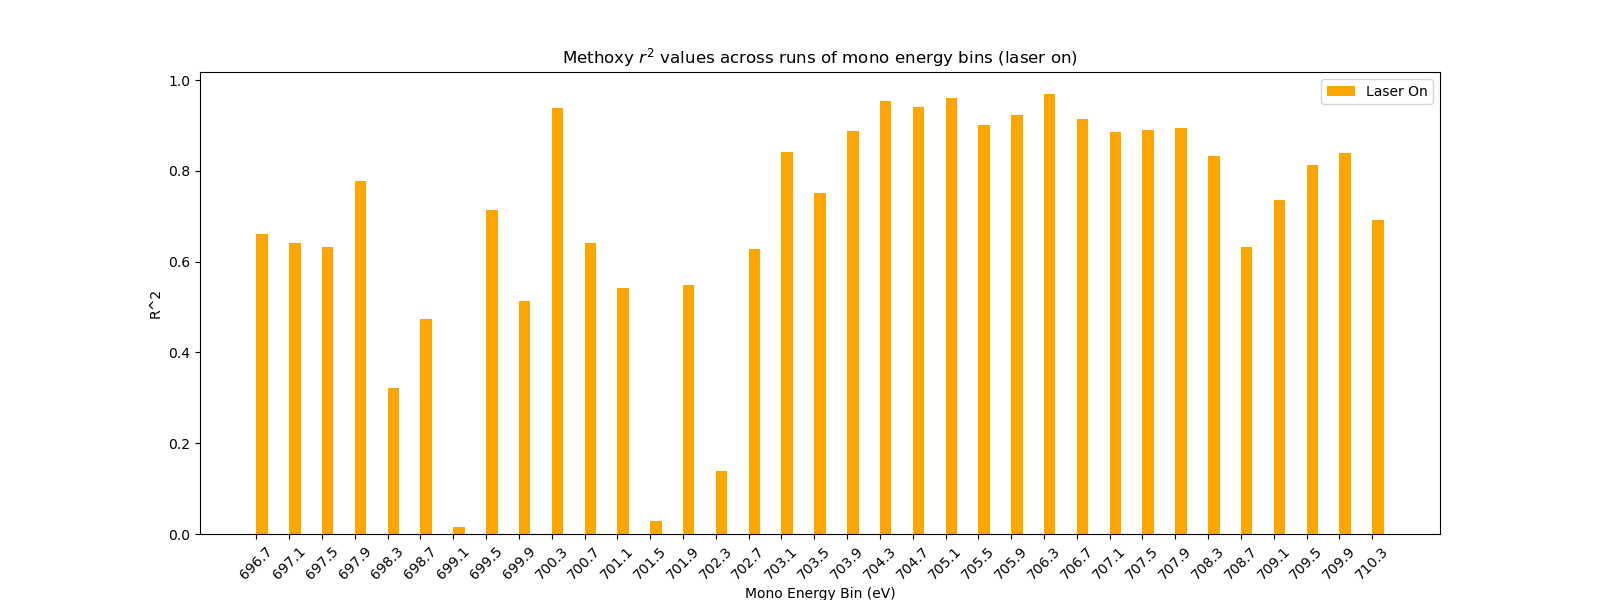

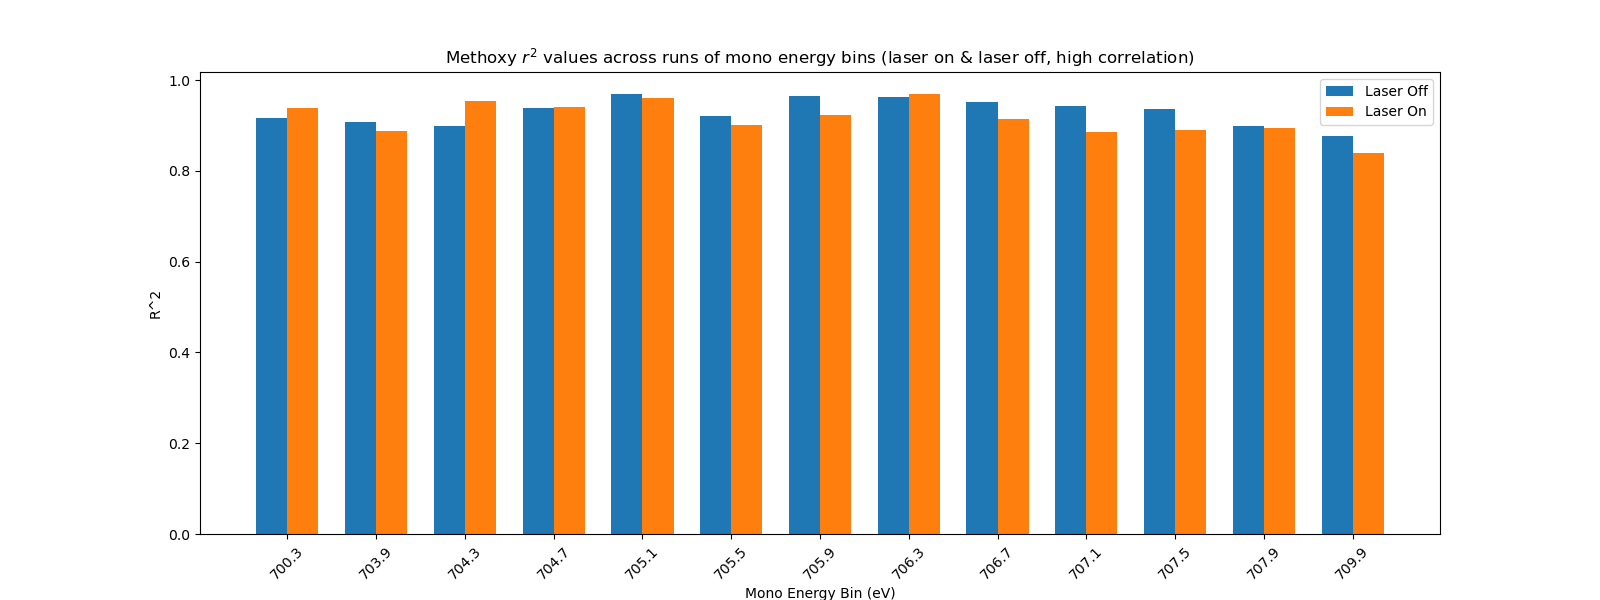

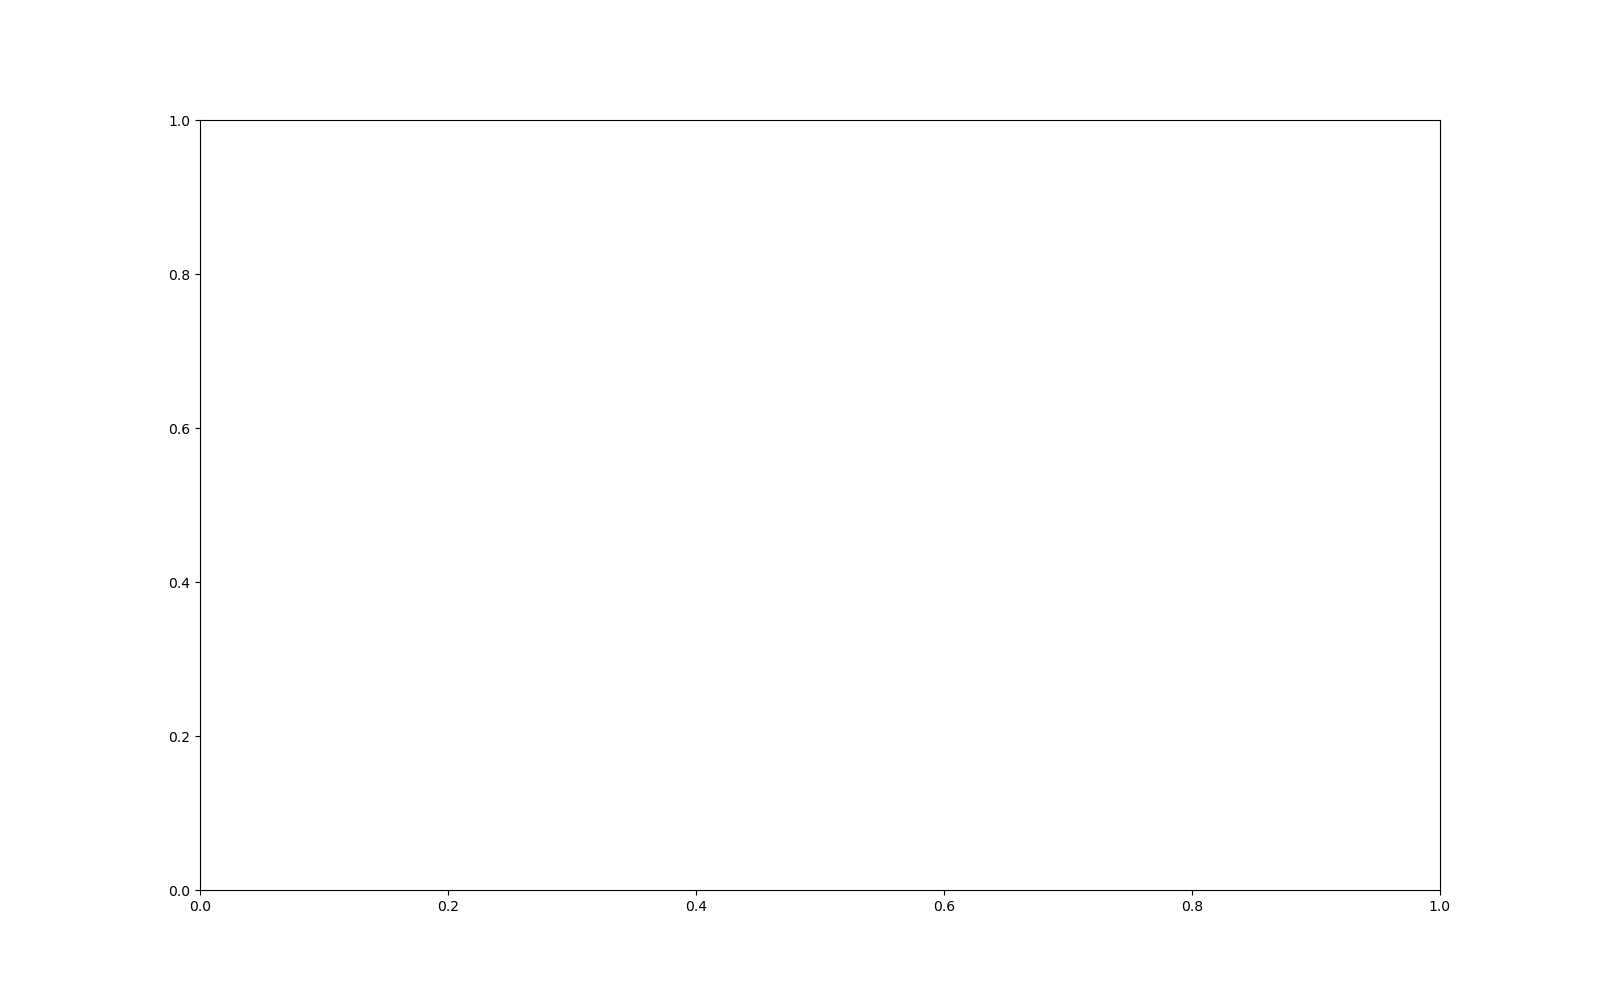

In [318]:
# loop through all bins

methoxy_off_r2 = []
methoxy_on_r2 = []
methoxy_off_f_r2 = []
methoxy_on_f_r2 = []

for i in range(len(scanvar)):
    
    x1 = methoxy_i0_off[:,i]
    y1 = methoxy_sos_off[:,i]
    
    x2 = methoxy_i0_on[:,i]
    y2 = methoxy_sos_on[:,i]
    
    x3 = methoxy_i0_off_f[:,i]
    y3 = methoxy_sos_off_f[:,i]
    
    x4 = methoxy_i0_on_f[:,i]
    y4 = methoxy_sos_on_f[:,i]
    
    # find the r^2 for each bin
    m1, b1, r1, p1, std_err1 = st.linregress(x1, y1)
    m2, b2, r2, p2, std_err2 = st.linregress(x2, y2)
    m3, b3, r3, p3, std_err3 = st.linregress(x3, y3)
    m4, b4, r4, p4, std_err4 = st.linregress(x4, y4)
    
    
    methoxy_off_r2.append(r1**2)
    methoxy_on_r2.append(r2**2)
    methoxy_off_f_r2.append(r3**2)
    methoxy_on_f_r2.append(r4**2)
    




# pinpoiint all the runs that have r^2 values over 0.8 for both laser on and laser off
mask_high_r2 = (np.array(methoxy_off_r2) > 0.8) & (np.array(methoxy_on_r2) > 0.8)
mask_low_r2 = (np.array(methoxy_off_r2) < 0.8) & (np.array(methoxy_on_r2) < 0.8)

plt.figure(figsize = (16,6))
x_bar = np.arange(len(scanvar))
width = 0.35
# plt.bar(x_bar - width/2, np.array(methoxy_off_r2), width, label = "Laser Off")
plt.bar(x_bar + width/2, np.array(methoxy_on_r2), width, label = "Laser On", color = 'orange')
plt.xticks(x_bar, labels = [f'{x:.1f}' for x in np.array(scanvar)], rotation = 45)
plt.xlabel('Mono Energy Bin (eV)')
plt.ylabel('R^2')
plt.title('Methoxy $r^2$ values across runs of mono energy bins (laser on)')
# plt.xlim(-1, len(scanvar)-17.5)
plt.legend()

plt.figure(figsize=(16,6))

x_bar = np.arange(sum(mask_high_r2))
width = 0.35
plt.bar(x_bar - width/2, np.array(methoxy_off_r2)[mask_high_r2], width, label = "Laser Off")
plt.bar(x_bar + width/2, np.array(methoxy_on_r2)[mask_high_r2], width, label = "Laser On")
# plt.bar(x_bar - width/2, methoxy_off_f_r2, width/2, label = "Laser Off Filtered", alpha = 0.5)
# plt.bar(x_bar + width/2, methoxy_on_f_r2, width/2, label = "Laser On Filtered", alpha = 0.5)
plt.xticks(x_bar, labels = [f'{x:.1f}' for x in np.array(scanvar)[mask_high_r2]], rotation = 45)
plt.xlabel('Mono Energy Bin (eV)')
plt.ylabel('R^2')
plt.title('Methoxy $r^2$ values across runs of mono energy bins (laser on & laser off, high correlation)')
# plt.xlim(-1, len(scanvar)-17.5)
plt.legend()


plt.figure(figsize=(16,6))
x_bar = np.arange(sum(mask_low_r2))
width = 0.35
plt.bar(x_bar - width/2, np.array(methoxy_off_r2)[mask_low_r2], width, label = "Laser Off")
plt.bar(x_bar + width/2, np.array(methoxy_on_r2)[mask_low_r2], width, label = "Laser On")
# plt.bar(x_bar - width/2, methoxy_off_f_r2, width/2, label = "Laser Off Filtered", alpha = 0.5)
# plt.bar(x_bar + width/2, methoxy_on_f_r2, width/2, label = "Laser On Filtered", alpha = 0.5)
plt.xticks(x_bar, labels = [f'{x:.1f}' for x in np.array(scanvar)[mask_low_r2]], rotation = 45)
plt.xlabel('Mono Energy Bin (eV)')
plt.ylabel('R^2')
plt.title('Methoxy $r^2$ values across runs of mono energy bins (laser on & laser off, low correlation)')
# plt.xlim(-1, len(scanvar)-17.5)
plt.ylim(0,1)
plt.legend()
plt.show()



##################### RUn Filtered ####################### rf stands for run filtered

fig, ax = plt.subplots(1, 1, figsize=(16, 10))



# fit a best fit line to see the correlation


methoxy_off_r2_rf = []
methoxy_on_r2_rf = []

for i in range(len(scanvar)):
    
    x1_rf = methoxy_i0_off_kept[:][i]
    y1_rf = methoxy_sos_off_kept[:][i]

    x2_rf = methoxy_i0_on_kept[:][i]
    y2_rf = methoxy_sos_on_kept[:][i]
    
    m1_rf, b1_rf, r1_value_rf, p1_value_rf, std_err1_rf = st.linregress(x1_rf,y1_rf)

    m2_rf, b2_rf, r2_value_rf, p2_value_rf, std_err2_rf = st.linregress(x2_rf,y2_rf)
    
    
    
    methoxy_off_r2_rf.append(r1_value_rf**2)
    methoxy_on_r2_rf.append(r2_value_rf**2)

x_bar = np.arange(len(scanvar))
width = 0.35
plt.bar(x_bar - width/2, np.array(methoxy_off_r2_rf), width, label = "Laser Off")
plt.bar(x_bar + width/2, np.array(methoxy_on_r2_rf), width, label = "Laser On")
plt.xticks(x_bar, labels = [f'{x:.1f}' for x in np.array(scanvar)], rotation = 45)
plt.xlabel('Mono Energy Bin (eV)')
plt.ylabel('R^2')
plt.title('Methoxy $r^2$ values across runs of mono energy bins (laser on & laser off, Runs Filtered)')
# plt.xlim(-1, len(scanvar)-17.5)
plt.legend()


plt.figure(figsize = (16,6))
plt.bar(x_bar - width/2, np.array(methoxy_off_r2_rf) - np.array(methoxy_off_r2), width, label = "Laser Off")
plt.bar(x_bar + width/2, np.array(methoxy_on_r2_rf)-np.array(methoxy_on_r2), width, label = "Laser On")
plt.xticks(x_bar, labels = [f'{x:.1f}' for x in np.array(scanvar)], rotation = 45)
plt.xlabel('Mono Energy Bin (eV)')
plt.ylabel('R^2 Improvement')
plt.title('Methoxy $r^2$ values across runs of mono energy bins (laser on & laser off, Runs Filtered Difference)')
# plt.xlim(-1, len(scanvar)-17.5)
plt.legend()


### Quantifying how non linear the points are. Find the standard deviation of each bin across the runs 
- for each bin, we have an arbitrary standard deviation that measures how spread out the data is
- so to compared the normalized and unnormalized I am going to have to scale them to around the same size. 

- find the mean of each distribution. multiply the normalized version with the binning factor to have them be able to be visually side by side. Then doing the standard deviation honestly would make more sense. 
    - i think maybe reshaping the matrices might help us here.



#### Plot out as line plots

### overlaying PFY by run to see if there is any shift

(18, 35)


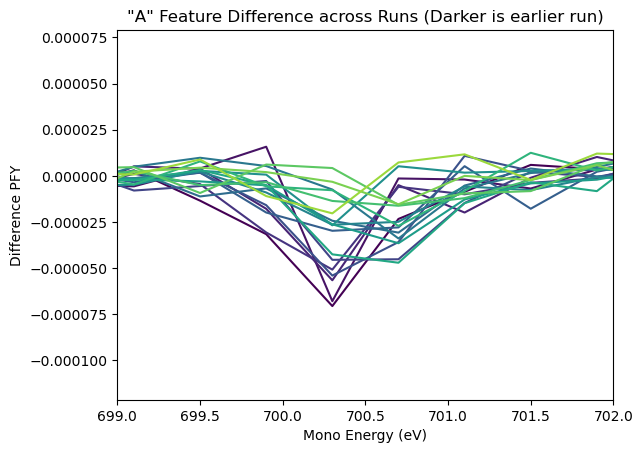

In [ ]:
color_gradient = plt.cm.viridis(np.linspace(0,0.85,len(runs)))

diff_PFY = PFY_on_mean_runs - mean_over_runs

print(diff_PFY.shape)

for i,_ in enumerate(diff_PFY):
    plt.plot(scanvar, diff_PFY[i], color=color_gradient[i])
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Difference PFY')
plt.title("\"A\" Feature Difference across Runs (Darker is earlier run)")
plt.xlim([699, 702])
plt.show()


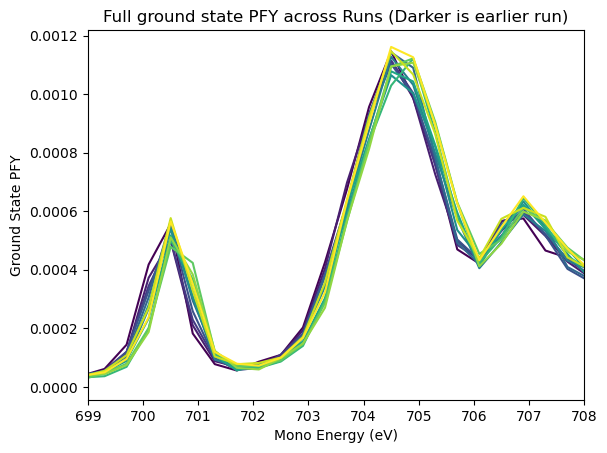

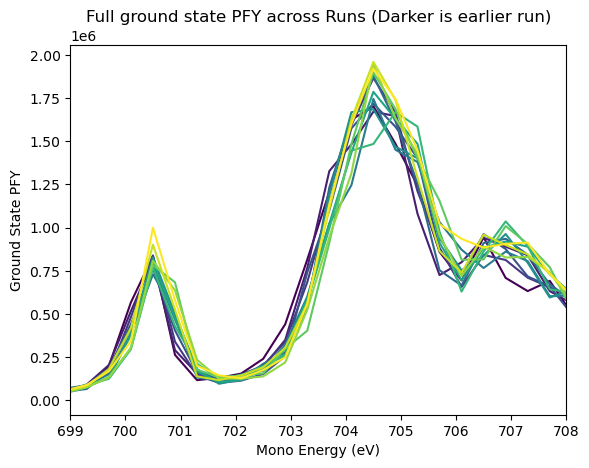

In [177]:
color_gradient = plt.cm.viridis(np.linspace(0,1,len(pyridine_selected_runs_v2)))

plt.figure()
for i,_ in enumerate(pyridine_sos_off_norm):
    plt.plot(scanvar, pyridine_sos_off_norm[i], color=color_gradient[i])
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Ground State PFY')
plt.title("Full ground state PFY across Runs (Darker is earlier run)")
plt.xlim([699, 708])
#plt.ylim([0, 0.0008])
# plt.legend()
plt.show()


plt.figure()
for i,_ in enumerate(pyridine_sos_on):
    plt.plot(scanvar, pyridine_sos_on[i], color=color_gradient[i])
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Ground State PFY')
plt.title("Full ground state PFY across Runs (Darker is earlier run)")
plt.xlim([699, 708])
#plt.ylim([0, 0.0008])
plt.show()


[178, 179, 180, 181, 182, 184, 185, 186, 188, 236, 237, 238, 249, 250]


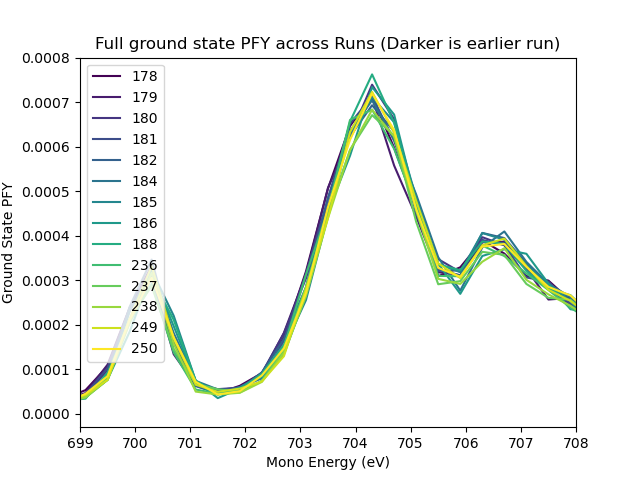

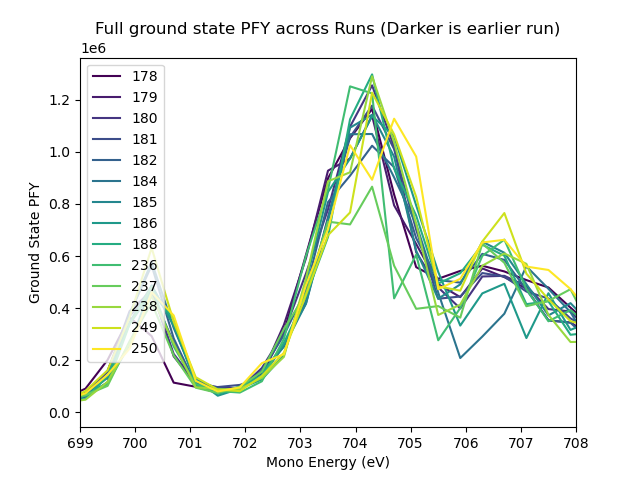

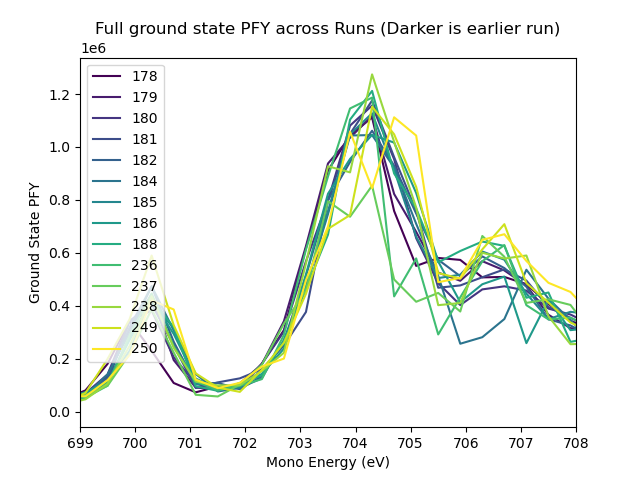

[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True]


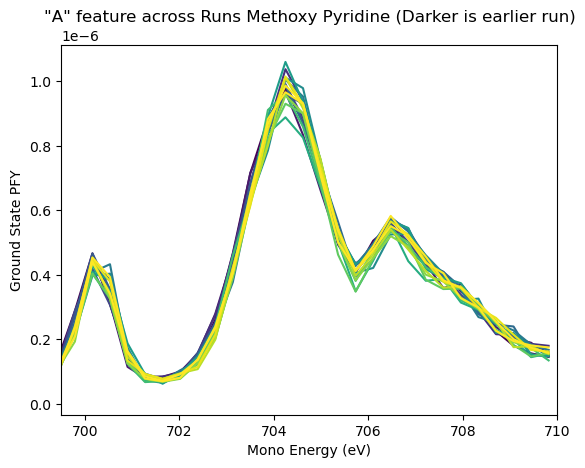

In [ ]:
color_gradient = plt.cm.viridis(np.linspace(0,1.1,len(methoxy_runs)))

methoxy_runs = np.array([178, 179, 180, 181, 182, 184, 185, 186, 188,235, 236, 237, 238, 248, 249, 250, 252])
methoxy_runs_excluded = 234

run_mask = methoxy_runs != methoxy_runs_excluded

methoxy_mean_over_runs_filtered = methoxy_mean_over_runs[run_mask]
methoxy_runs_filtered = methoxy_runs[run_mask]

methoxy_PFY_over_sos_runs = methoxy_PFY_off_sos_runs[run_mask]
methoxy_PFY_over_sos_err_runs = methoxy_PFY_off_sos_err_runs[run_mask]

print(run_mask)
color_gradient = plt.cm.viridis(np.linspace(0,1.1,len(methoxy_runs_filtered)))

for i,_ in enumerate(methoxy_PFY_over_sos_runs):
    plt.plot(scanvar, methoxy_PFY_over_sos_runs[i], color=color_gradient[i])#label=methoxy_runs_filtered[i])
plt.xlabel('Mono Energy (eV)')
plt.ylabel('Ground State PFY')
plt.title("\"A\" feature across Runs Methoxy Pyridine (Darker is earlier run)")
plt.xlim([699.5, 710])
#plt.ylim([0, 0.0008])
# plt.legend()
plt.show()

## Averaging

In [4]:
def average(runs, sigma_tresh=2,
            despeckle=True, kernel_size=3, n_sigma=10,
            shot_roi=None, photons=False,
            sos_adu=True, mean=True, maps=False,
            pool_sos=False,
            run_filter=True, run_filter_kw=None,
            run_filter_base='_filtered', run_filter_min_runs=6,
            run_filter_couple_states=True, verbose=True,
            num_bins=33, bin_start=696.7, bin_end=709.9,
            bin_shifts=None, coverage_tol=0.05):
    """
    Reduce a list of runs and combine them into one averaged spectrum.
 
    Parameters
    ----------
    runs : sequence of int
    shot_roi : (lo, hi) or None
        Passed to reduce(). Pixel range summed for each shot's scalar.
    photons : bool
        Passed to reduce(). Runs droplet_to_photons. Off by default.
    sos_adu : bool
        Weighted-average the per-run ADU sum-over-sum. The primary result.
    mean : bool
        Also weighted-average the mean-method spectra.
    maps : bool
        Also weighted-average the mean-method 2-D maps. Off by default: it
        requires every run to share one emi_calib entry, and raises if they
        do not. The collapsed spectra are valid across an emi_calib
        boundary -- summing the emission axis is insensitive to how pixels
        are labelled.
    pool_sos : bool
        Pool the photon sos ingredients. Needs photons=True.
 
    Binning
    -------
    num_bins, bin_start, bin_end : int, float, float
        Passed to reduce(). They define the nominal grid, and so the
        energy axis of the output.
    bin_shifts : dict {run: shift_eV} or None
        Runs whose mono energy scale is offset from the rest. Each listed
        run is reduced on (bin_start + shift, bin_end + shift) with the
        same num_bins, so bin j covers the same physical interval in every
        run and all per-bin arrays combine index by index. Use a positive
        shift when that run's features sit at HIGHER mono energy than in
        the unshifted runs. The shift need not be a whole number of bins.
        Runs not listed are unshifted, and the output scanvar is taken
        from them, so at least one run must be unshifted.
    coverage_tol : float
        Fraction of one bin. A bin is flagged in partial_bins when the
        fraction of it covered by the mono scan differs by more than this
        across runs -- typically where a shifted run's grid overhangs the
        end of its scan. Flagged bins are kept, but they average a
        different set of runs than the rest of the spectrum.
 
    Run-level filtering
    -------------------
    run_filter : bool
        Build the across-run correlation mask and return the '_runfilt'
        and '_filtered_runfilt' variants alongside '' and '_filtered'.
        Rejects individual (run, bin) entries, so a run can be dropped in
        one mono bin and kept in another. That means the surviving
        population changes from bin to bin, and any residual per-run scale
        offset (sample density drift, gain drift) can imprint on the
        lineshape. Check run_filter_info_*['run_survival'] -- a run that
        fails in most bins is a bad run, not a bad bin, and is better
        removed from the `runs` list by hand.
    run_filter_base : '' or '_filtered'
        Which shot variant the run mask is DERIVED from. It is applied to
        both regardless, so this changes which runs get flagged, not what
        comes back.
 
        '_filtered' (default) is the better measurement: a run's summed ADU
        is a cleaner number once its bad shots are gone, so the run-to-run
        correlation is tighter and the filter more sensitive. Use '' to see
        what the run filter finds without reduce's shot-level cut -- expect
        wider scatter, a larger sigma estimate, and weaker rejection.
    run_filter_kw : dict
        Passed to filter_correlation, e.g. dict(sigma_thresh=1.8, trim_k=10).
    run_filter_min_runs : int
        Bins with fewer valid runs than this are left unfiltered.
    run_filter_couple_states : bool
        Keep only (run, bin) entries surviving in BOTH on and off, and
        apply that intersection to both. Default True: otherwise PFY_diff
        subtracts two different populations of runs, which is not a
        pump-probe difference. Costs data -- a run bad only in off is
        dropped from on too, and an empty off bin kills the matching on
        bin. Set False if you are studying on and off separately.
 
    Returns
    -------
    dict. Every headline key exists in four variants when run_filter=True:
        ''  '_filtered'  '_runfilt'  '_filtered_runfilt'
    and in the first two when it is False. Namely:
 
        PFY_{on,off,diff}_sosadu{v}[_err]
        PFY_{on,off,diff}_mean{v}[_err]
        {key}_n_used, {key}_runs, {key}_runs_err, {key}_pooled
        counts_{on,off}{v}, adu_total_*{v}, i0_sum_*{v}
        map_/err_{on,off}_mean{v}          (maps=True)
 
    plus, once:
        scanvar, runs, n_runs, frames_dropped_*, fzp_*, shot_norm
        bin_shifts                 (n_runs,)  shift applied to each run [eV]
        scanvar_ref_run            run whose axis defines scanvar
        bin_coverage               (n_runs, n_bins) fraction of each bin
                                   covered by that run's mono scan
        partial_bins               bin indices with uneven coverage
        run_keep_{on,off}          (n_runs, n_bins) bool
        run_filter_info_{on,off}   per-bin diagnostics
        run_filter_runs_kept, run_filter_base, run_filter_coupled
    """
    n_runs = len(runs)
    if n_runs == 0:
        raise ValueError("no runs given")
    if run_filter_kw is None:
        run_filter_kw = {}
    if run_filter_base not in ('', '_filtered'):
        raise ValueError("run_filter_base must be '' or '_filtered'")
 
    # ------------------------------------------------------------------
    # 0. Per-run bin shifts. An unknown run number is an error rather than
    #    a no-op, so a typo cannot silently leave a run unshifted.
    # ------------------------------------------------------------------
    if bin_shifts is None:
        bin_shifts = {}
    unknown = sorted(set(bin_shifts) - set(runs))
    if unknown:
        raise ValueError(f"bin_shifts lists runs that are not in `runs`: "
                         f"{unknown}")
    shifts = np.array([float(bin_shifts.get(run, 0.0)) for run in runs])
    unshifted = shifts == 0.0
    if not unshifted.any():
        raise ValueError("every run has a nonzero bin shift; at least one "
                         "run must use the nominal grid to define scanvar")
    if verbose and unshifted.sum() <= n_runs / 2:
        print(f"  warning: only {int(unshifted.sum())} of {n_runs} runs are "
              f"unshifted, but they still define the energy axis")
 
    # ------------------------------------------------------------------
    # 1. Reduce every run, keep the result dicts
    # ------------------------------------------------------------------
    if verbose:
        print(f"--- reducing {n_runs} runs ---")
 
    results = []
    for run, d in zip(runs, shifts):
        # return_raw=False is required: the per-shot 2-D arrays are ~0.5 GB
        # per run and every run is held simultaneously here
        results.append(reduce(run_num=run,
                              sigma_tresh=sigma_tresh,
                              num_bins=num_bins,
                              bin_start=bin_start + d, bin_end=bin_end + d,
                              despeckle=despeckle, kernel_size=kernel_size,
                              n_sigma=n_sigma, shot_roi=shot_roi,
                              photons=photons, return_raw=False))
        if verbose:
            tag = f" (bins shifted {d:+.3f} eV)" if d else ""
            print(f"--- finished reducing run {run}{tag} ---")
        gc.collect()
 
    def has(key):
        return key in results[0]
 
    # ------------------------------------------------------------------
    # 2. Energy axis. The unshifted runs define scanvar; every run must
    #    sit on scanvar + its own shift, or bin j means different energies
    #    in different runs and the average is nonsense.
    # ------------------------------------------------------------------
    ref = int(np.flatnonzero(unshifted)[0])
    scanvar = results[ref]['scanvar']
    for run, r, d in zip(runs, results, shifts):
        if not np.allclose(r['scanvar'], scanvar + d,
                           rtol=0, atol=1e-6, equal_nan=True):
            raise ValueError(
                f"run {run} (shift {d:+g} eV) is not on the energy axis of "
                f"run {runs[ref]} plus its shift; bin centres must match "
                f"across runs once shifts are removed")
 
    out = {'scanvar': scanvar, 'runs': np.asarray(runs), 'n_runs': n_runs,
           'run_filter': bool(run_filter),
           'bin_shifts': shifts, 'scanvar_ref_run': runs[ref],
           'num_bins': num_bins, 'bin_start': bin_start, 'bin_end': bin_end}
 
    # ------------------------------------------------------------------
    # 2a. Bin coverage per run, in the common frame. A shifted grid
    #     overhangs its run's scan at one end, so the edge bin(s) average
    #     a different set of runs. Kept, but flagged.
    # ------------------------------------------------------------------
    edges = np.linspace(bin_start, bin_end, num_bins + 1)
    width = edges[1] - edges[0]
    if has('mono_range'):
        coverage = np.empty((n_runs, num_bins))
        for i, (r, d) in enumerate(zip(results, shifts)):
            m_lo, m_hi = r['mono_range']
            overlap = (np.minimum(m_hi, edges[1:] + d) -
                       np.maximum(m_lo, edges[:-1] + d))
            coverage[i] = np.clip(overlap / width, 0.0, 1.0)
        coverage = np.nan_to_num(coverage, nan=0.0)
    else:
        # reduce() output without mono_range: only fully empty bins visible
        coverage = np.array([(r['counts_on'] + r['counts_off']) > 0
                             for r in results], dtype=float)
        if verbose:
            print("  note: reduce() did not return mono_range; the coverage "
                  "flag detects empty bins only, not partially covered ones")
    out['bin_coverage'] = coverage
    out['partial_bins'] = np.flatnonzero(np.ptp(coverage, axis=0) >
                                         coverage_tol)
 
    # ------------------------------------------------------------------
    # 2c. Build the run-level mask, before anything is stacked, so every
    #     downstream quantity sees one consistent set of surviving runs
    # ------------------------------------------------------------------
    keep = {}
    if run_filter:
        if not has(f'adu_total_on{run_filter_base}'):
            raise ValueError(f"run_filter needs adu_total_*/i0_sum_* with "
                             f"suffix '{run_filter_base}' from reduce(); "
                             f"this result set does not have them")
        if n_runs < run_filter_min_runs and verbose:
            print(f"  warning: {n_runs} runs is thin for a run-level "
                  f"correlation filter; most bins will be left unfiltered")
 
        for state in ('on', 'off'):
            k, inf = build_run_mask(results, state,
                                    min_runs=run_filter_min_runs,
                                    source_suffix=run_filter_base,
                                    verbose=verbose, **run_filter_kw)
            keep[state], out[f'run_filter_info_{state}'] = k, inf
 
        # couple the two states: keep only (run, bin) entries surviving in
        # BOTH, so on and off average an identical population of runs and
        # PFY_diff is a pump-probe difference rather than a difference
        # between two different sets of runs
        if run_filter_couple_states:
            both = keep['on'] & keep['off']
            keep['on'], keep['off'] = both, both.copy()
 
        for state in ('on', 'off'):
            out[f'run_keep_{state}'] = keep[state]
 
        alive = keep['on'].any(axis=1)
        out['run_filter_runs_kept'] = np.asarray(runs)[alive]
        out['run_filter_base'] = run_filter_base
        out['run_filter_coupled'] = bool(run_filter_couple_states)
 
        if verbose:
            dead = np.asarray(runs)[~alive]
            if dead.size:
                print(f"  runs removed entirely: {dead.tolist()}")
            surv = out['run_filter_info_on']['run_survival']
            worst = np.argsort(surv)[:3]
            print("  lowest per-run survival: " + ", ".join(
                f"run {runs[j]} {100*surv[j]:.0f}%" for j in worst))
 
    # ------------------------------------------------------------------
    #     Variant table: output suffix -> (reduce shot suffix, apply mask)
    #
    #     The two filters are orthogonal, so this is their cross product.
    #     One mask, both shot variants.
    # ------------------------------------------------------------------
    VARIANTS = {
        '':                  ('',          False),
        '_filtered':         ('_filtered', False),
    }
    if run_filter:
        VARIANTS['_runfilt'] = ('',          True)
        VARIANTS['_filtered_runfilt'] = ('_filtered', True)
    suffixes = list(VARIANTS)
    out['variants'] = suffixes
 
    def sstack(fmt, state, suffix):
        """Stack a per-run key across runs and apply the run mask if this
        variant calls for it. fmt uses {s} for state, {x} for the reduce
        shot suffix.
 
        Rejected entries become NaN for floats and 0 for integer counts --
        a zero count carries zero weight in every count-weighted expression
        and every division is guarded by where=N > 0, so the integer case
        needs no NaN."""
        shot_x, apply_mask = VARIANTS[suffix]
        arr = np.array([r[fmt.format(s=state, x=shot_x)] for r in results])
        if not apply_mask:
            return arr
        m = keep[state]
        if arr.ndim == 3:              # (n_runs, n_bins, n_pix) maps
            m = m[:, :, None]
        if np.issubdtype(arr.dtype, np.integer):
            return np.where(m, arr, 0)
        return np.where(m, arr.astype(float), np.nan)
 
    def _store(wa, key):
        """Write a weighted_average result."""
        out[key] = wa['x_wav']
        out[f'{key}_err'] = wa['sigma_cons']
        out[f'{key}_err_internal'] = wa['sigma_wav']
        out[f'{key}_n_used'] = wa['n_used']
 
    # shot counts, per run and summed. Needed by the mean method, so
    # stacked unconditionally.
    for _st in ('on', 'off'):
        for _sx in suffixes:
            _c = sstack('counts_{s}{x}', _st, _sx)
            out[f'counts_{_st}{_sx}'] = _c.sum(axis=0)
            out[f'counts_{_st}{_sx}_runs'] = _c
 
    # ------------------------------------------------------------------
    # 2b. Emission axis. A mismatch matters only for the 2-D maps: the
    #     spectra sum over the emission axis, so how pixels are LABELLED
    #     cannot affect them. Raise only when maps are actually built.
    # ------------------------------------------------------------------
    out['emi_calib_uniform'] = None
    if has('E_emi'):
        E_emi = results[0]['E_emi']
        calib_of = {run: r.get('emi_calib') for run, r in zip(runs, results)}
        mismatch = [run for run, r in zip(runs, results)
                    if not np.allclose(r['E_emi'], E_emi)]
        if not mismatch:
            out['E_emi'] = E_emi
            out['emi_calib'] = results[0].get('emi_calib')
            out['emi_calib_uniform'] = True
        else:
            out['emi_calib_uniform'] = False
            out['emi_calib_by_run'] = calib_of
            groups = {}
            for run in runs:
                c = calib_of[run]
                groups.setdefault(tuple(np.round(c, 8)) if c is not None
                                  else (), []).append(int(run))
            if maps:
                pretty = '\n    '.join(f"{v}  ->  calib {k}"
                                       for k, v in groups.items())
                raise ValueError(
                    f"runs straddle an emi_calib boundary, so pixel j means a "
                    f"different emission energy in different runs and the 2-D "
                    f"maps cannot be averaged:\n    {pretty}\n"
                    f"  Either split the run list into those groups, or leave "
                    f"maps=False -- summing the emission axis is insensitive "
                    f"to how pixels are labelled, so the spectra are fine.")
            if verbose:
                print(f"  note: {len(groups)} emi_calib entries in this run "
                      f"set {list(groups.values())}; spectra are unaffected, "
                      f"but no emission axis is written so the RIXS/ET plots "
                      f"are unavailable")
 
    # ------------------------------------------------------------------
    # 3. ADU sum-over-sum -- the primary result
    # ------------------------------------------------------------------
    out['sosadu_available'] = False
    if sos_adu and has('PFY_on_sosadu'):
        for state in ('on', 'off'):
            for suffix in suffixes:
                key = f'PFY_{state}_sosadu{suffix}'
                vals = sstack('PFY_{s}_sosadu{x}', state, suffix)
                errs = sstack('PFY_{s}_sosadu{x}_err', state, suffix)
 
                _store(weighted_average(vals, errs, axis=0), key)
                out[f'{key}_runs'] = vals
                out[f'{key}_runs_err'] = errs
 
                # pooled form: should match x_wav to rounding
                A = sstack('adu_total_{s}{x}', state, suffix)
                B = sstack('i0_sum_{s}{x}', state, suffix)
                As, Bs = np.nansum(A, axis=0), np.nansum(B, axis=0)
                out[f'{key}_pooled'] = np.divide(
                    As, Bs, out=np.full(Bs.shape, np.nan), where=Bs > 0)
                out[f'adu_total_{state}{suffix}'] = As
                out[f'i0_sum_{state}{suffix}'] = Bs
                out[f'adu_total_{state}{suffix}_runs'] = A
                out[f'i0_sum_{state}{suffix}_runs'] = B
 
        for suffix in suffixes:
            on, off = f'PFY_on_sosadu{suffix}', f'PFY_off_sosadu{suffix}'
            out[f'PFY_diff_sosadu{suffix}'] = out[on] - out[off]
            out[f'PFY_diff_sosadu{suffix}_err'] = np.sqrt(
                out[f'{on}_err']**2 + out[f'{off}_err']**2)
            out[f'PFY_diff_sosadu{suffix}_pooled'] = (
                out[f'{on}_pooled'] - out[f'{off}_pooled'])
        out['sosadu_available'] = True
    elif sos_adu and verbose:
        print("  note: reduce() did not return PFY_*_sosadu; skipping the "
              "ADU sum-over-sum")
 
    # ------------------------------------------------------------------
    # 4. Mean method
    # ------------------------------------------------------------------
    if mean:
        for state in ('on', 'off'):
            for suffix in suffixes:
                key = f'PFY_{state}_mean{suffix}'
                vals = sstack('PFY_{s}_mean{x}', state, suffix)
                errs = sstack('PFY_{s}_mean{x}_err', state, suffix)
                cnts = out[f'counts_{state}{suffix}_runs']
 
                _store(weighted_average(vals, errs, axis=0), key)
                out[f'{key}_countwavg'] = count_weighted(vals, cnts)
                out[f'{key}_runs'] = vals
                out[f'{key}_runs_err'] = errs
 
        for suffix in suffixes:
            on, off = f'PFY_on_mean{suffix}', f'PFY_off_mean{suffix}'
            out[f'PFY_diff_mean{suffix}'] = out[on] - out[off]
            out[f'PFY_diff_mean{suffix}_err'] = np.sqrt(
                out[f'{on}_err']**2 + out[f'{off}_err']**2)
 
    # ------------------------------------------------------------------
    # 4b. Mean-method 2-D maps, same weighting, one weight per (bin, pixel)
    # ------------------------------------------------------------------
    out['maps_available'] = False
    if maps:
        missing = [f'{p}_{s}_mean{x}'
                   for p in ('map', 'err') for s in ('on', 'off')
                   for x in ('', '_filtered') if not has(f'{p}_{s}_mean{x}')]
        if missing:
            if verbose:
                print(f"  note: reduce() did not return {missing[0]} "
                      f"(+{len(missing)-1} more); skipping the 2-D maps")
        else:
            for state in ('on', 'off'):
                for suffix in suffixes:
                    mkey = f'map_{state}_mean{suffix}'
                    wa = weighted_average(
                        sstack('map_{s}_mean{x}', state, suffix),
                        sstack('err_{s}_mean{x}', state, suffix), axis=0)
                    out[mkey] = wa['x_wav']
                    out[f'err_{state}_mean{suffix}'] = wa['sigma_cons']
                    out[f'{mkey}_n_used'] = wa['n_used']
            for suffix in suffixes:
                out[f'map_diff_mean{suffix}'] = (out[f'map_on_mean{suffix}'] -
                                                 out[f'map_off_mean{suffix}'])
                out[f'err_diff_mean{suffix}'] = np.sqrt(
                    out[f'err_on_mean{suffix}']**2 +
                    out[f'err_off_mean{suffix}']**2)
            out['maps_available'] = True
            gc.collect()
 
    # ------------------------------------------------------------------
    # 5. Photon sos -- pool counts and exposure, divide once
    # ------------------------------------------------------------------
    if pool_sos and has('photons_on_total'):
        for state in ('on', 'off'):
            for suffix in suffixes:
                key = f'PFY_{state}_sos{suffix}'
                A, B, val, err = pool_sos(
                    sstack('photons_{s}{x}_total', state, suffix),
                    sstack('i0_sum_{s}{x}', state, suffix))
                out[key] = val
                out[f'{key}_err'] = err
                out[f'photons_{state}{suffix}_total'] = A
        for suffix in suffixes:
            on, off = f'PFY_on_sos{suffix}', f'PFY_off_sos{suffix}'
            out[f'PFY_diff_sos{suffix}'] = out[on] - out[off]
            out[f'PFY_diff_sos{suffix}_err'] = np.sqrt(out[f'{on}_err']**2 +
                                                       out[f'{off}_err']**2)
    elif pool_sos and verbose:
        print("  note: no photon data (reduce ran with photons=False); "
              "skipping the photon sos")

 
    # ------------------------------------------------------------------
    # 7. Diagnostics
    # ------------------------------------------------------------------
    with np.errstate(invalid='ignore'):
        for _k in ('frames_dropped_on', 'frames_dropped_off',
                   'fzp_on', 'fzp_off'):
            out[_k] = np.nanmean(np.array([r[_k] for r in results]), axis=0)
    if has('n_lowi0_dropped'):
        out['n_lowi0_dropped'] = np.array([r['n_lowi0_dropped']
                                           for r in results])
 
    if verbose and out['sosadu_available']:
        # weighted vs pooled: these agree to ~1e-4 when the runs are
        # consistent in yield, and degrade by orders of magnitude when one
        # run is off. A run-consistency check that costs nothing.
        for suffix in suffixes:
            k = f'PFY_on_sosadu{suffix}'
            with np.errstate(invalid='ignore', divide='ignore'):
                rel = np.abs(out[k] / out[f'{k}_pooled'] - 1)
            nu = out[f'{k}_n_used']
            thin = np.where(nu < 3)[0]
            print(f"\nADU sos (on, '{suffix or 'raw'}'): weighted vs pooled "
                  f"agree to {np.nanmax(rel):.2e}")
            if thin.size:
                print(f"  bins with fewer than 3 surviving runs: "
                      f"{thin.tolist()}")
 
        # each shot variant against itself plus the run filter
        if run_filter:
            for shot_x in ('', '_filtered'):
                a = out[f'PFY_on_sosadu{shot_x}']
                b = out[f'PFY_on_sosadu{shot_x}_runfilt']
                fin = np.isfinite(a) & np.isfinite(b) & (a != 0)
                if not fin.any():
                    continue
                sh = 100 * np.nanmax(np.abs(b[fin]/a[fin] - 1))
                print(f"\nrun filter moved '{shot_x or 'raw'}' on spectrum "
                      f"by at most {sh:.2f}%")
                if sh > 5:
                    print("  large shift -- check it is removing outliers "
                          "rather than reshaping the scan")
 
    # uneven-coverage bins: kept, but they average a different set of runs.
    # n_used should roughly equal full + partial; if it equals n_runs where
    # some runs are empty, the empty runs are leaking into the average.
    if verbose and out['partial_bins'].size:
        nu = out.get('PFY_on_sosadu_n_used')
        print(f"\nbins with uneven coverage across runs (kept, flagged):")
        for j in out['partial_bins']:
            c = coverage[:, j]
            full = int((c >= 1 - coverage_tol).sum())
            empty = int((c <= coverage_tol).sum())
            line = (f"  bin {j:2d}  {scanvar[j]:.2f} eV: {full} full, "
                    f"{n_runs - full - empty} partial, {empty} empty")
            if nu is not None:
                line += f"  | on sosadu n_used = {int(nu[j])}"
            print(line)
 
    return out

### Averaging Function for multiple Runs

In [5]:
pyridine_runs = [112,114,115,116,117,118,119,120,121,122,123,127,138,139,140,141,145]
methoxy_selected_runs = [178,179,180, 181, 182, 184, 185, 186, 188, 236, 249, 250]
pyridine_selected_runs = [112, 114, 115,116, 117,118, 119, 120, 121, 122,123, 127, 129, 141]
methoxy_runs = [178,179,180, 181, 182, 184, 185, 186, 188, 236, 237, 238, 249, 250, 252]
methoxy_selected_runs_v2 = [179,180, 181, 182, 184, 185,186, 237, 238, 249, 250]
# set the run parameters so that we do not remove intensity outliers but instead mainly deviation from the linear line
a = average(pyridine_runs, sigma_tresh = 2, run_filter_kw=dict(sigma_thresh=2, trim_k=10), num_bins = 33, bin_start = 696.7, bin_end = 709.9, bin_shifts = {112: -0.12, 114: -0.12, 115: -0.12, 116: -0.12, 117: -0.12})


--- reducing 17 runs ---
  h5 read: 6.4s
  dropped 6 shots below 10% of median I0 (3.864e+06)


/sdf/home/j/jwang343/miniconda3/envs/dachemrixs/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


  processing: 2.1s
run 112: 8.6s, peak RSS 3.4 GB
--- finished reducing run 112 (bins shifted -0.120 eV) ---
  h5 read: 17.2s
  dropped 7 shots below 10% of median I0 (3.929e+06)
  processing: 2.3s
run 114: 19.5s, peak RSS 3.5 GB
--- finished reducing run 114 (bins shifted -0.120 eV) ---
  h5 read: 9.8s
  dropped 19 shots below 10% of median I0 (3.870e+06)
  processing: 3.9s
run 115: 13.7s, peak RSS 3.5 GB
--- finished reducing run 115 (bins shifted -0.120 eV) ---
  h5 read: 12.2s
  processing: 2.4s
run 116: 14.6s, peak RSS 3.5 GB
--- finished reducing run 116 (bins shifted -0.120 eV) ---
  h5 read: 8.6s
  dropped 15 shots below 10% of median I0 (3.919e+06)
  processing: 2.2s
run 117: 10.8s, peak RSS 3.5 GB
--- finished reducing run 117 (bins shifted -0.120 eV) ---
  h5 read: 14.1s
  dropped 263 shots below 10% of median I0 (3.928e+06)
  processing: 2.2s
run 118: 16.4s, peak RSS 3.5 GB
--- finished reducing run 118 ---
  h5 read: 11.2s
  dropped 6 shots below 10% of median I0 (3.969e+0

In [30]:
methoxy_early_runs = [178, 179, 180, 181]
methoxy_middle_runs = [182, 185, 188, 236, 237, 238, 249, 250]
methoxy_late_runs = [184, 186, 252]
a1 = average(methoxy_runs, sigma_tresh = 2, run_filter_kw = dict(sigma_thresh=2, trim_k=10),num_bins = 33, bin_start = 696.9, bin_end = 710.1, bin_shifts = {178: -0.03, 179: -0.03, 180: -0.03, 181: -0.03, 184: 0.03, 186: 0.03, 252: 0.03})

--- reducing 15 runs ---
  h5 read: 0.9s
  dropped 822 shots below 10% of median I0 (3.669e+06)


/sdf/home/j/jwang343/miniconda3/envs/dachemrixs/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


  processing: 4.5s
run 178: 5.4s, peak RSS 6.1 GB
--- finished reducing run 178 (bins shifted -0.030 eV) ---
  h5 read: 0.8s
  processing: 2.3s
run 179: 3.2s, peak RSS 6.1 GB
--- finished reducing run 179 (bins shifted -0.030 eV) ---
  h5 read: 0.8s
  processing: 2.3s
run 180: 3.1s, peak RSS 6.1 GB
--- finished reducing run 180 (bins shifted -0.030 eV) ---
  h5 read: 0.8s
  processing: 2.3s
run 181: 3.1s, peak RSS 6.1 GB
--- finished reducing run 181 (bins shifted -0.030 eV) ---
  h5 read: 0.9s
  processing: 2.4s
run 182: 3.2s, peak RSS 6.1 GB
--- finished reducing run 182 ---
  h5 read: 0.7s
  dropped 1289 shots below 10% of median I0 (3.596e+06)
  processing: 2.3s
run 184: 3.1s, peak RSS 6.1 GB
--- finished reducing run 184 (bins shifted +0.030 eV) ---
  h5 read: 0.9s
  processing: 2.4s
run 185: 3.3s, peak RSS 6.1 GB
--- finished reducing run 185 ---
  h5 read: 1.0s
  dropped 1867 shots below 10% of median I0 (3.592e+06)
  processing: 2.4s
run 186: 3.4s, peak RSS 6.1 GB
--- finished 

### Plot out the runs but with the large SLVS I0 deviation bins highlighted

In [27]:
for i in a.keys():
    print(i)

scanvar
runs
n_runs
run_filter
run_filter_info_on
run_filter_info_off
run_keep_on
run_keep_off
run_filter_runs_kept
run_filter_base
run_filter_coupled
variants
counts_on
counts_on_runs
counts_on_filtered
counts_on_filtered_runs
counts_on_runfilt
counts_on_runfilt_runs
counts_on_filtered_runfilt
counts_on_filtered_runfilt_runs
counts_off
counts_off_runs
counts_off_filtered
counts_off_filtered_runs
counts_off_runfilt
counts_off_runfilt_runs
counts_off_filtered_runfilt
counts_off_filtered_runfilt_runs
emi_calib_uniform
emi_calib_by_run
sosadu_available
PFY_on_sosadu
PFY_on_sosadu_err
PFY_on_sosadu_err_internal
PFY_on_sosadu_n_used
PFY_on_sosadu_runs
PFY_on_sosadu_runs_err
PFY_on_sosadu_pooled
adu_total_on
i0_sum_on
adu_total_on_runs
i0_sum_on_runs
PFY_on_sosadu_filtered
PFY_on_sosadu_filtered_err
PFY_on_sosadu_filtered_err_internal
PFY_on_sosadu_filtered_n_used
PFY_on_sosadu_filtered_runs
PFY_on_sosadu_filtered_runs_err
PFY_on_sosadu_filtered_pooled
adu_total_on_filtered
i0_sum_on_filtere

In [31]:
"""
PFY spectrum plotting for the averaged ChemRIXS output.

Everything takes the dict returned by average().

    plot_pfy(a, ...)                one row: on/off overlay + difference
    plot_pfy_runfilt(a, ...)        two rows: without and with the run
                                    filter, shared y per column
    plot_difference_overlay(a, ...) both differences on one axes

SUFFIXES
--------
average() returns two orthogonal filters as a cross product, so every key
comes in up to four variants:

    ''                    no shot filter, no run filter
    '_filtered'           shot filter only
    '_runfilt'            run filter only
    '_filtered_runfilt'   both

Every function here takes `filtered` (the shot-level filter inside
reduce) and `runfilt` (the across-run filter in average) as separate
booleans, and builds the suffix from the pair.

METHOD
------
    'sosadu'  sum-over-sum, A / sum(I0)   -- the default
    'mean'    mean of the per-shot normalised values
"""

import matplotlib.pyplot as plt
import numpy as np

C_ON, C_OFF, C_DIFF = 'tab:blue', 'tab:orange', 'tab:blue'

_METHODS = {
    'sosadu': ('sum-over-sum', r'Normalized SVLS ($\Sigma$SVLS/$\Sigma$I0)'),
    'mean':   ('mean method',  'Normalized SVLS (SVLS/I0)'),
}


# ----------------------------------------------------------------------
# helpers
# ----------------------------------------------------------------------
def _check_method(method):
    if method not in _METHODS:
        raise ValueError(f"method must be one of {list(_METHODS)}, "
                         f"got {method!r}")
    return _METHODS[method]


def _sfx(filtered=True, runfilt=False):
    """Build the average() key suffix from the two filter flags.

    (True,  False) -> '_filtered'
    (False, True ) -> '_runfilt'
    (True,  True ) -> '_filtered_runfilt'
    """
    return ('_filtered' if filtered else '') + ('_runfilt' if runfilt else '')


def _tag(filtered, runfilt):
    """Short human label for a variant."""
    parts = ['shot-filtered' if filtered else 'unfiltered']
    if runfilt:
        parts.append('run-filtered')
    return ', '.join(parts)


def _spectrum(a, state, method='sosadu', filtered=True, runfilt=False,
              err_key='_err'):
    """(x, y, err) for one state."""
    _check_method(method)
    k = f'PFY_{state}_{method}{_sfx(filtered, runfilt)}'
    if k not in a:
        avail = sorted(q for q in a if q.startswith(f'PFY_{state}_{method}')
                       and not q.endswith(('_runs', '_runs_err', '_err',
                                           '_err_internal', '_n_used',
                                           '_pooled', '_countwavg')))
        extra = ("  Run average() with run_filter=True to get the "
                 "'_runfilt' variants." if runfilt else "")
        raise KeyError(f"'{k}' is not in this dict. Available: {avail}.{extra}")
    e = a.get(f'{k}{err_key}', a[f'{k}_err'])
    return (np.asarray(a['scanvar'], float), np.asarray(a[k], float),
            np.asarray(e, float))


def _difference(a, method='sosadu', filtered=True, runfilt=False,
                err_key='_err'):
    """(x, diff, err). Uses the stored difference when present, else builds
    it; on and off are disjoint shot sets so the errors add in quadrature."""
    _check_method(method)
    x = np.asarray(a['scanvar'], float)
    dk = f'PFY_diff_{method}{_sfx(filtered, runfilt)}'
    if dk in a and err_key == '_err':
        return x, np.asarray(a[dk], float), np.asarray(a[f'{dk}_err'], float)
    _, on, on_e = _spectrum(a, 'on', method, filtered, runfilt, err_key)
    _, off, off_e = _spectrum(a, 'off', method, filtered, runfilt, err_key)
    return x, on - off, np.sqrt(on_e**2 + off_e**2)


def _band(ax, x, y, e, color, label=None, marker='o', ms=3, lw=1.4,
          alpha=0.2, zorder=2):
    ax.fill_between(x, y - e, y + e, color=color, alpha=alpha, linewidth=0,
                    zorder=zorder)
    ax.plot(x, y, color=color, marker=marker, ms=ms, lw=lw, label=label,
            zorder=zorder + 1)


def _zero(ax, x):
    ax.hlines(0, np.nanmin(x), np.nanmax(x), colors='gray',
              linestyles='dashed', linewidth=0.6)


def _runtag(a):
    r = np.asarray(a.get('runs', []))
    return f'Runs {r[0]}-{r[-1]}' if r.size else 'Averaged runs'


def _runfilt_note(a, state='on'):
    """One-line summary of what the run filter removed, or '' if absent."""
    k = a.get(f'run_keep_{state}')
    if k is None:
        return ''
    kept, total = int(k.sum()), int(k.size)
    n_bins = k.shape[1]
    per_bin = k.sum(axis=0)
    gone = np.asarray(a.get('runs', []))[~k.any(axis=1)]
    s = (f'{100*(1-kept/total):.1f}% of (run,bin) entries dropped; '
         f'{per_bin.min()}-{per_bin.max()} runs per bin')
    if gone.size:
        s += f'; runs {gone.tolist()} gone entirely'
    return s


# ======================================================================
# 1. One row: on/off overlay + difference
# ======================================================================
def _draw_row(axrow, a, method, filtered, runfilt, err_key, show_n_used):
    """Fill a 2-axes row: overlay on the left, difference on the right."""
    label, ylab = _METHODS[method]

    x, on, on_e = _spectrum(a, 'on', method, filtered, runfilt, err_key)
    _, off, off_e = _spectrum(a, 'off', method, filtered, runfilt, err_key)
    _, diff, derr = _difference(a, method, filtered, runfilt, err_key)

    _band(axrow[0], x, on, on_e, C_ON, 'Laser On')
    _band(axrow[0], x, off, off_e, C_OFF, 'Laser Off')
    axrow[0].set_ylabel(ylab)
    axrow[0].legend(fontsize=9)

    _band(axrow[1], x, diff, derr, C_DIFF, 'On - Off')
    _zero(axrow[1], x)
    axrow[1].set_ylabel(ylab)
    axrow[1].legend(fontsize=9)

    if show_n_used:
        nu = a.get(f'PFY_on_{method}{_sfx(filtered, runfilt)}_n_used')
        if nu is not None:
            nu = np.asarray(nu)
            axrow[0].text(0.02, 0.03,
                          f'runs per bin: {nu.min()}-{nu.max()}',
                          transform=axrow[0].transAxes, fontsize=8,
                          color='0.35')
    return x


def plot_pfy(a, method='sosadu', filtered=True, runfilt=False,
             err_key='_err', figsize=(18, 5.5), title=None,
             show_n_used=True):
    """
    One row, two panels: on/off spectra with 1-sigma bands, and the
    on-off difference with its band.
    """
    label, _ = _check_method(method)
    fig, ax = plt.subplots(1, 2, figsize=figsize)
    x = _draw_row(ax, a, method, filtered, runfilt, err_key, show_n_used)

    tag = _tag(filtered, runfilt)
    ax[0].set_xlabel('Mono Energy (eV)')
    ax[1].set_xlabel('Mono Energy (eV)')
    ax[0].set_title(f'{_runtag(a)} ({tag}): PFY, {label}')
    ax[1].set_title(f'{_runtag(a)} ({tag}): Difference (On - Off)')

    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig, ax


# ======================================================================
# 2. Two rows: without and with the run filter
# ======================================================================
def plot_pfy_runfilt(a, method='sosadu', filtered=True, err_key='_err',
                     figsize=(18, 10), share_y=True, title=None,
                     show_n_used=True):
    """
    Four panels in two rows, the main run-filter comparison.

        top-left     on/off overlay, no run filter
        top-right    difference,     no run filter
        bottom-left  on/off overlay, run filter applied
        bottom-right difference,     run filter applied

    All four carry 1-sigma error bands.

    `filtered` selects the shot-level filter for BOTH rows, so the only
    thing changing between top and bottom is the run filter. With
    share_y=True each column shares a y-axis, which matters: without it
    matplotlib autoscales the two rows independently and a difference
    spectrum that barely moved can look transformed.

    Needs average(..., run_filter=True).
    """
    label, _ = _check_method(method)
    if f'PFY_on_{method}{_sfx(filtered, True)}' not in a:
        raise KeyError(
            f"no run-filtered keys in this dict -- rerun average() with "
            f"run_filter=True (looked for "
            f"'PFY_on_{method}{_sfx(filtered, True)}')")

    fig, ax = plt.subplots(2, 2, figsize=figsize,
                           sharex=True, sharey='col' if share_y else 'none')

    for row, rf in enumerate((False, True)):
        _draw_row(ax[row], a, method, filtered, rf, err_key, show_n_used)

    ax[0, 0].set_title(f'PFY, no run filter')
    ax[0, 1].set_title('Difference (On - Off), no run filter')
    ax[1, 0].set_title('PFY, run filter applied')
    ax[1, 1].set_title('Difference (On - Off), run filter applied')
    for c in (0, 1):
        ax[1, c].set_xlabel('Mono Energy (eV)')

    note = _runfilt_note(a)
    sup = title or (f'{_runtag(a)} ({_tag(filtered, False)}): '
                    f'run filter comparison, {label}')
    fig.suptitle(sup + (f'\n{note}' if note else ''), fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    return fig, ax


# ======================================================================
# 3. Both differences on one axes
# ======================================================================
def plot_difference_overlay(a, method='sosadu', filtered=True,
                            err_key='_err', figsize=(10, 6), ax=None,
                            title=None):
    """
    The difference spectrum with and without the run filter, overlaid.

    Use this rather than plot_pfy_runfilt when you want to see how far the
    run filter actually moved the difference -- overlapping bands mean it
    changed nothing beyond the error bars.
    """
    _check_method(method)
    x1, y1, e1 = _difference(a, method, filtered, False, err_key)
    x2, y2, e2 = _difference(a, method, filtered, True, err_key)

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    _band(ax, x1, y1, e1, C_ON, 'no run filter')
    _band(ax, x2, y2, e2, C_OFF, 'run filter applied')
    _zero(ax, x1)

    ax.set_xlabel('Mono Energy (eV)')
    ax.set_ylabel(_METHODS[method][1])
    ax.set_title(title or f'Difference PFY (On - Off), '
                          f'{_METHODS[method][0]} ({_tag(filtered, False)})')
    ax.legend()
    fig.tight_layout()
    return fig, ax

(<Figure size 1000x600 with 2 Axes>,
 array([<Axes: title={'center': 'Runs 178-252 (shot-filtered): PFY, sum-over-sum'}, xlabel='Mono Energy (eV)', ylabel='Normalized SVLS ($\\Sigma$SVLS/$\\Sigma$I0)'>,
        <Axes: title={'center': 'Runs 178-252 (shot-filtered): Difference (On - Off)'}, xlabel='Mono Energy (eV)', ylabel='Normalized SVLS ($\\Sigma$SVLS/$\\Sigma$I0)'>],
       dtype=object))

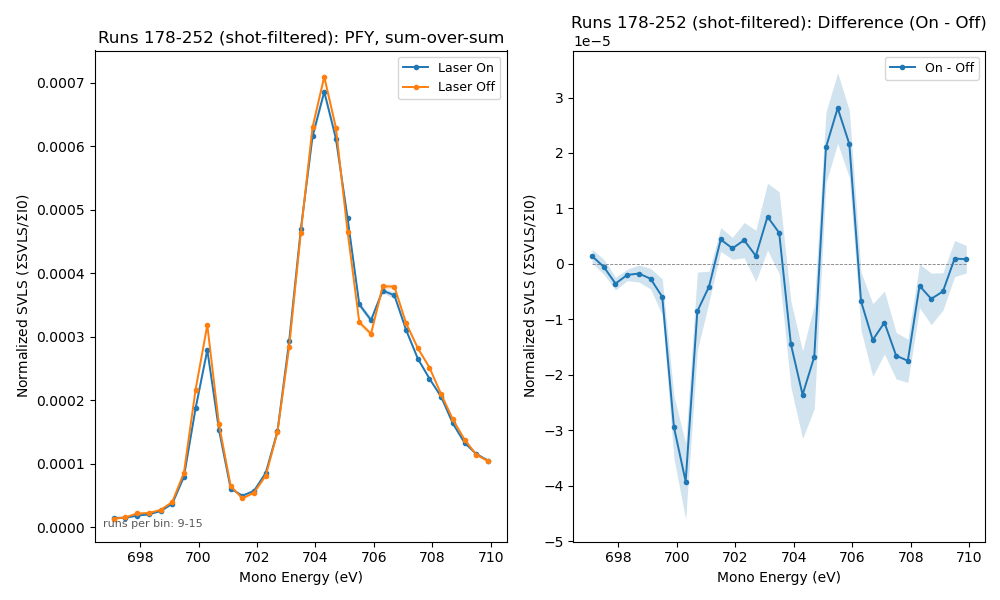

In [37]:
plot_pfy(a1, filtered = True, runfilt=False, figsize = (10,6))
# plot_difference_overlay(a, filtered = False)

In [39]:
# ======================================================================
# 4. Two datasets side by side
# ======================================================================
C_A, C_B = 'tab:purple', 'tab:green'   # dataset 1 / dataset 2
 
 
def _scale_factor(a, method, filtered, runfilt, scale):
    """One factor per dataset, taken from its GROUND STATE spectrum.
 
    The same factor is then applied to the ground state, the excited state
    and the difference, so the three panels stay on a common footing --
    scaling each panel by its own peak would make the difference look as
    large as the XANES and destroy the comparison.
    """
    if scale in (None, 'none'):
        return 1.0
    _, off, _ = _spectrum(a, 'off', method, filtered, runfilt)
    if scale == 'peak':
        f = np.nanmax(np.abs(off))
    elif scale == 'mean':
        f = np.nanmean(off)
    else:
        raise ValueError("scale must be 'none', 'peak' or 'mean', "
                         f"got {scale!r}")
    return float(f) if np.isfinite(f) and f != 0 else 1.0
 
 
def plot_two_datasets(a1, a2, label1='MeOPy', label2='Py',
                      method='sosadu', filtered=False, runfilt=False,
                      err_key='_err', scale='none', figsize=(19, 5.5),
                      colors=(C_A, C_B), title=None):
    """
    Two average() outputs overlaid, three panels, 1-sigma bands throughout.
 
        left    difference (On - Off) for both datasets
        middle  ground state  (Laser Off) -- XANES
        right   excited state (Laser On)  -- XANES
 
    Each dataset is plotted against its own scanvar, so different binning
    between the two is fine.
 
    scale : 'none' | 'peak' | 'mean'
        Absolute units, or divide each dataset by its own ground-state peak
        or mean. Use a scaling when the two samples differ in
        concentration or exposure and you want to compare LINESHAPE; the
        difference panel is then in the same units as the XANES panels and
        reads as a fraction of the ground-state signal.
 
    runfilt : bool
        Applies to both datasets. They must have been averaged with the
        same run_filter setting for the comparison to mean anything.
    """
    label, ylab = _check_method(method)
 
    f1 = _scale_factor(a1, method, filtered, runfilt, scale)
    f2 = _scale_factor(a2, method, filtered, runfilt, scale)
 
    fig, ax = plt.subplots(1, 3, figsize=figsize)
 
    for a, lbl, c, f in ((a1, label1, colors[0], f1),
                         (a2, label2, colors[1], f2)):
        x, d, de = _difference(a, method, filtered, runfilt, err_key)
        _band(ax[0], x, d/f, de/f, c, lbl)
 
        _, off, off_e = _spectrum(a, 'off', method, filtered, runfilt, err_key)
        _band(ax[1], x, off/f, off_e/f, c, lbl)
 
        _, on, on_e = _spectrum(a, 'on', method, filtered, runfilt, err_key)
        _band(ax[2], x, on/f, on_e/f, c, lbl)
 
    _zero(ax[0], np.asarray(a1['scanvar'], float))
 
    if scale in (None, 'none'):
        yl = ylab
    else:
        yl = f'{ylab}\n(/ ground-state {scale})'
    ax[0].set_ylabel(yl)
 
    for a_, t in zip(ax, ('Difference (On - Off)',
                          'Ground state (Laser Off)',
                          'Excited state (Laser On)')):
        a_.set_xlabel('Mono Energy (eV)')
        a_.set_title(t)
        a_.legend(fontsize=9)
 
    tag = _tag(filtered, runfilt)
    fig.suptitle(title or f'{label1} vs {label2}: PFY, {label} ({tag})')
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig, ax
 

(<Figure size 1900x550 with 3 Axes>,
 array([<Axes: title={'center': 'Difference (On - Off)'}, xlabel='Mono Energy (eV)', ylabel='Normalized SVLS ($\\Sigma$SVLS/$\\Sigma$I0)'>,
        <Axes: title={'center': 'Ground state (Laser Off)'}, xlabel='Mono Energy (eV)'>,
        <Axes: title={'center': 'Excited state (Laser On)'}, xlabel='Mono Energy (eV)'>],
       dtype=object))

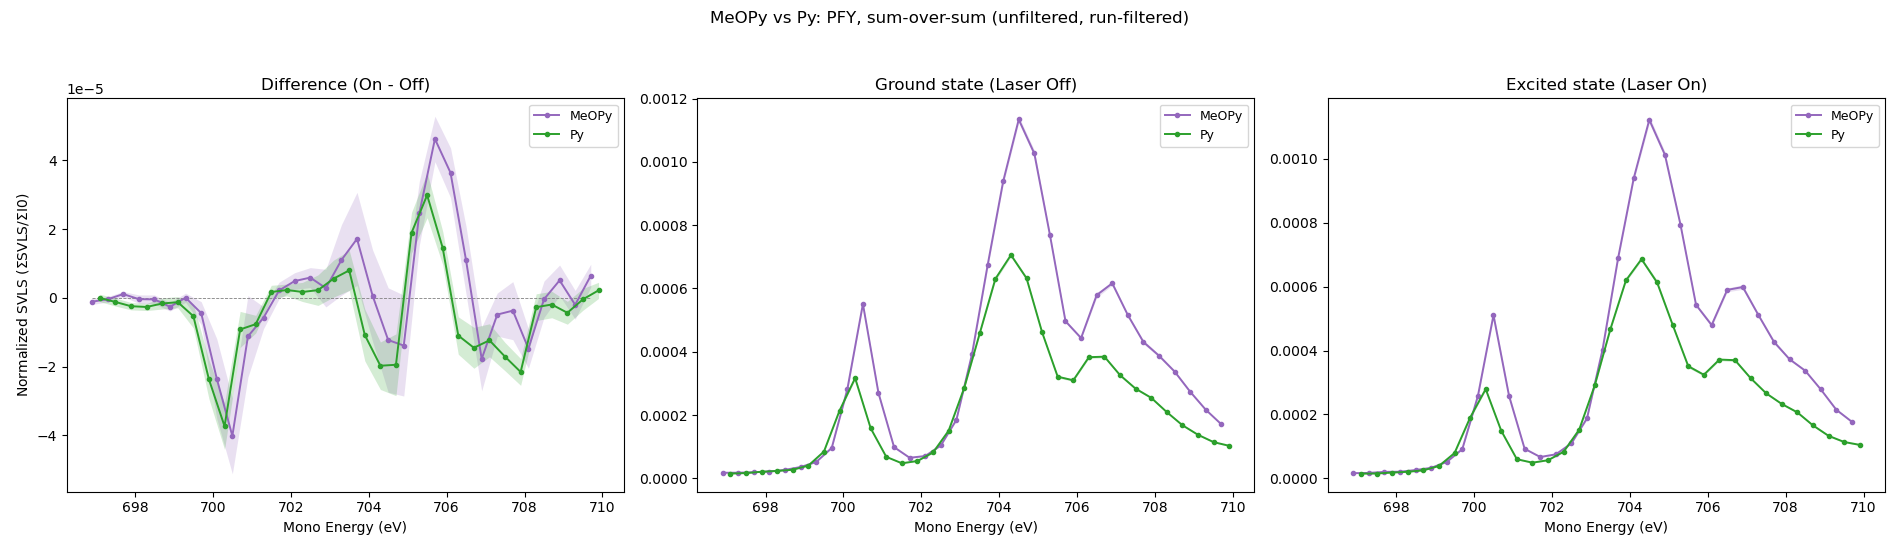

In [41]:
plot_two_datasets(a, a1, filtered = False, runfilt= True)

## START OF IMPLEMENTING SUM OVER SUM STUFF